# TUH cross-validation study: fold models, agreement and errors by cohort

Five-fold, patient-grouped cross-validation of the three v3 brain-age models on the compact CV copy of
`all_both_v3` (`all_both_v3_cvcompact`). The CV pool is TUAB train+val plus all TUEG recordings; the
**official TUAB test set (274 recordings) is never in any fold**, so every fold model is also scored on
it. Fold $k$: test = fold $k$, val = fold $k{+}1 \bmod 5$, train = the other three
(`labram/data/cross_validation.py`).

| experiment | model | schedule |
|---|---|---|
| `cvbase` | Exp4base: 23 channels with T1/T2 zero-filled where missing, mean pooling over patch tokens, no condition vectors | 5 epochs, 1 warm-up |
| `cvctrl` | Exp4ctrl: class-token pooling + status/pathology condition vectors in the head | 10 epochs, 3 warm-up |
| `cvaug` | Exp4-augT1T2: `cvctrl` + T1/T2 batch dropout ($p=0.2$, 1–2 channels) with L2 consistency $\lambda=0.1$ | 10 epochs, 3 warm-up |

All three use the speed settings (batch 128, fused attention, 5 min per recording per epoch). The notebook is
data-driven: it shows every fold model that has been scored so far and can be re-run as more folds finish.

**Inputs.** `scripts/eval_cv_folds.py` rebuilds each fold exactly as training did and writes
`cv_eval.csv` (metrics per fold × split × source × cohort) and `cv_preds.json` (per-recording predictions,
years). The predictions are per-patient derived data and stay outside git (TUH data-use agreement); set
`LABRAM_CV_EVAL` to their directory.

**Contents.**
1. Inputs: the scored fold models (Table 1.1).
2. Fold statistics per experiment: over fold models and the median ensemble (Eqs. (2.1)–(2.7), Tables 2.1–2.4, Figure 2.1).
3. Correlation and agreement between models (Eqs. (3.1)–(3.5), Tables 3.1–3.2, Figures 3.1–3.3).
4. Predicted vs. true age by data source and pathology group (Eqs. (4.1)–(4.3), Figures 4.1–4.*K*+1).
5. Error bars by cohort, pathology group and age (Eqs. (5.1)–(5.2), Tables 5.1–5.2, Figures 5.1–5.3).
6. Findings, generated from the data.

In [1]:
import json
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

if not any(os.path.isdir(os.path.join(p, "labram")) for p in sys.path):
    sys.path.insert(0, os.path.abspath(".."))
from labram.eval import cv_compare as cc
from labram.eval.age_plots import assert_max_columns, figure_heading, numbered_table, panel_labels

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)

EVAL_DIR = os.environ.get("LABRAM_CV_EVAL", "/data/datasets/EEG-public/TUH_EEG/_state/cohort_runs/cv_eval")
DATA = os.environ.get("LABRAM_CV_DATA", "/data/datasets/EEG-public/TUH_EEG/cohorts/all_both_v3_cvcompact")
EXPS = {"cvbase": "Exp4base (mean pool)", "cvctrl": "Exp4ctrl (cls + cond)", "cvaug": "Exp4-augT1T2 (λ 0.1)"}
COLORS = {"cvbase": "tab:blue", "cvctrl": "tab:orange", "cvaug": "tab:green"}
STATUS_COLORS = {"normal": "tab:green", "abnormal": "tab:red", "not_available": "tab:gray"}
AGE_EDGES = [0, 20, 30, 40, 50, 60, 70, 80, 120]          # the cohorts are adults (18+)
AGE_LABELS = ["<20"] + [f"{a}–{b - 1}" for a, b in zip(AGE_EDGES[1:-2], AGE_EDGES[2:-1])] + [f"{AGE_EDGES[-2]}+"]
MIN_GROUP = 30            # smallest pathology group shown

preds = cc.load_predictions(os.path.join(EVAL_DIR, "cv_preds.json"))
ORDER = [e for e in EXPS if e in preds] + [e for e in preds if e not in EXPS]
d = cc.long_frame(preds)

# recording metadata: source corpus, status and pathology flags (conditions_v1.npz)
cohort = pd.read_parquet(os.path.join(DATA, "cohort.parquet"), columns=["stem", "subject", "corpora"])
source = pd.Series(np.where(cohort.corpora.str.contains("tuab"), "TUAB", "TUEG"), index=cohort.stem)
z = np.load(os.path.join(DATA, "conditions_v1.npz"), allow_pickle=True)
cmeta = json.loads(str(z["meta"]))
status = pd.Series(np.array(cmeta["status"])[z["tokens/status"][:, 0].argmax(1)], index=z["stems"])
patho = pd.DataFrame(z["tokens/pathology"][:, 0] > 0, index=z["stems"], columns=cmeta["pathology"])
d["source"] = d.stem.map(source)
d["status"] = d.stem.map(status)
assert d.source.notna().all() and d.status.notna().all()
print(f"{len(ORDER)} experiments, {d.groupby('exp').fold.nunique().sum()} fold models, "
      f"{d.stem.nunique()} recordings scored")

3 experiments, 9 fold models, 29309 recordings scored


## 1. Inputs

### Table 1.1. Scored fold models

One row per experiment: the folds whose model has been scored, the epoch of each fold's selected
checkpoint (`checkpoint-best.pth`, lowest val MAE), and the number of recordings per split. `val` and
`test` are the fold's own held-out folds; `heldout` is the official TUAB test set. The last column checks
that the fold partition is the same for every experiment, which the paired comparisons in Sections 2–3 rely on.

In [2]:
csv = pd.read_csv(os.path.join(EVAL_DIR, "cv_eval.csv"))
best_epoch = csv.groupby(["exp", "fold"]).epoch.first()
test_sets = d[d.split == "test"].groupby(["exp", "fold"]).stem.apply(frozenset)
same_partition = all(test_sets.xs(k, level="fold").nunique() == 1 for k in test_sets.index.get_level_values("fold").unique())
rows = []
for e in ORDER:
    s = d[d.exp == e]
    folds = sorted(s.fold.unique())
    rows.append({"experiment": e, "model": EXPS.get(e, e), "folds scored": ", ".join(map(str, folds)),
                 "best epoch per fold (1-based)": ", ".join(str(int(best_epoch[(e, k)]) + 1) for k in folds),
                 **{f"n {sp} / fold": int(round(s[s.split == sp].groupby("fold").stem.nunique().mean()))
                    for sp in ("val", "test", "heldout")},
                 "same folds as other exps": same_partition})
numbered_table(pd.DataFrame(rows).set_index("experiment"), "1.1", "Scored fold models")

,model,folds scored,best epoch per fold (1-based),n val / fold,n test / fold,n heldout / fold,same folds as other exps
experiment,,,,,,,
cvbase,Exp4base (mean pool),"0, 1, 2, 3, 4","5, 5, 5, 5, 5",5807,5807,274,True
cvctrl,Exp4ctrl (cls + cond),"2, 3, 4","8, 10, 10",5820,5869,274,True
cvaug,Exp4-augT1T2 (λ 0.1),1,9,5811,5765,274,True


## 2. Fold statistics per experiment

For a set $S$ of recordings with true age $y_i$ and predicted age $\hat y_i$ (the mean over the
recording's windows, de-normalized with the fold's training-target statistics; years), the per-model
metrics are (`labram/eval/cv_compare.py::metrics`)

$$ \mathrm{MAE} = \frac{1}{|S|}\sum_{i\in S}\lvert \hat y_i - y_i\rvert \tag{2.1} $$

$$ \mathrm{RMSE} = \Big(\frac{1}{|S|}\sum_{i\in S}(\hat y_i - y_i)^2\Big)^{1/2} \tag{2.2} $$

$$ R^2 = 1 - \frac{\sum_{i\in S}(\hat y_i - y_i)^2}{\sum_{i\in S}(y_i - \bar y_S)^2} \tag{2.3} $$

$$ \mathrm{bias} = \frac{1}{|S|}\sum_{i\in S}(\hat y_i - y_i) \tag{2.4} $$

where $\bar y_S$ is the mean true age of $S$. Over the $K$ fold models $m_1,\dots,m_K$ of one experiment,
with $\mathrm{MAE}_k$ the MAE of model $m_k$ on its set,

$$ \overline{\mathrm{MAE}} = \frac{1}{K}\sum_k \mathrm{MAE}_k, \qquad
   s = \Big(\frac{1}{K-1}\sum_k(\mathrm{MAE}_k-\overline{\mathrm{MAE}})^2\Big)^{1/2}, \qquad
   \widetilde{\mathrm{MAE}} = \operatorname{median}_k \mathrm{MAE}_k \tag{2.5} $$

(sample sd, `ddof=1`). The sets are: **CV val** and **CV test** (the fold's own held-out folds, all
sources), **TUEG test** (the TUEG recordings of the test fold) and **TUAB test** (the official 274
recordings, the same for every fold model).

In [3]:
def per_fold(frame, set_masks, cohorts=("all", "normal", "abnormal", "not_available")):
    rows = []
    for name, mask in set_masks.items():
        for (e, k), g in frame[mask].groupby(["exp", "fold"]):
            for c in cohorts:
                sub = g if c == "all" else g[g.status == c]
                if len(sub) >= 2:
                    rows.append({"exp": e, "fold": k, "set": name, "cohort": c, **cc.metrics(sub.pred, sub.true)})
    return pd.DataFrame(rows)

SETS = {"CV val": d.split == "val", "CV test": d.split == "test",
        "TUEG test": (d.split == "test") & (d.source == "TUEG"), "TUAB test": d.split == "heldout"}
pf = per_fold(d, SETS)

### Table 2.1. MAE over fold models

Per experiment and set: the number of fold models $K$, the median $\widetilde{\mathrm{MAE}}$ and
mean ± sd $\overline{\mathrm{MAE}} \pm s$ of the per-fold MAE (Eqs. (2.1), (2.5)), all recordings, in years.

In [4]:
def pm(s):
    return f"{s.mean():.2f} ± {s.std():.2f}" if len(s) > 1 else f"{s.mean():.2f}"

t = pf[pf.cohort == "all"].groupby(["exp", "set"]).MAE.agg(K="count", median="median", mean_sd=pm).unstack("set")
t = t.reorder_levels([1, 0], axis=1)[[(s, c) for s in SETS for c in ("K", "median", "mean_sd")]]
numbered_table(t.loc[ORDER], "2.1", "MAE over fold models")

### Table 2.2. Over fold models by cohort

TUAB test and TUEG test split by status (normal / abnormal; TUEG also *not available*, recordings without a
report label): MAE mean ± sd over fold models (Eqs. (2.1), (2.5)), the mean $R^2$ (Eq. (2.3)) and the mean
bias (Eq. (2.4)), years. $R^2$ is relative to each cohort's own age spread, so it is not comparable across cohorts.

In [5]:
sub = pf[pf.set.isin(["TUAB test", "TUEG test"])]
t = sub.groupby(["exp", "set", "cohort"]).agg(n=("n", "mean"), MAE=("MAE", pm), R2=("R2", "mean"),
                                               bias=("bias", "mean")).reset_index()
t["cohort"] = pd.Categorical(t.cohort, ["all", "normal", "abnormal", "not_available"])
t = t.sort_values(["set", "cohort"]).pivot_table(index=["set", "cohort"], columns="exp",
                                                 values=["MAE", "R2", "bias"], aggfunc="first", observed=True)
t = t.reindex(columns=[(m, e) for m in ("MAE", "R2", "bias") for e in ORDER])
numbered_table(t, "2.2", "Over fold models by cohort")

### Table 2.3. Median over fold models (ensemble) and pooled out-of-fold

The **ensemble** prediction of an experiment for recording $i$ of the TUAB test is the median (or mean) of
its $K$ fold models' predictions (`cv_compare.py::ensemble`),

$$ \hat y_i^{\mathrm{med}} = \operatorname{median}_k \hat y_{i,k}, \qquad \hat y_i^{\mathrm{mean}} = \frac1K\sum_k \hat y_{i,k}, \tag{2.6} $$

scored with Eqs. (2.1)–(2.3). Each pool recording is in exactly one test fold, so it has exactly one
**out-of-fold** prediction $\hat y_i^{\mathrm{oof}} = \hat y_{i,k(i)}$, from the model $k(i)$ that never
saw its patient; the pooled out-of-fold score is

$$ \mathrm{MAE}^{\mathrm{oof}} = \frac{1}{|P|}\sum_{i\in P}\lvert \hat y_i^{\mathrm{oof}} - y_i\rvert \tag{2.7} $$

over the TUEG part $P$ of the scored test folds. Columns: single model = $\overline{\mathrm{MAE}}$ (2.5);
ens. median / mean = Eq. (2.6); normal and abnormal of the median ensemble; TUEG out-of-fold = Eq. (2.7)
with its $R^2$ and its number of recordings.

In [6]:
ens = cc.ensemble(d, "heldout", "median").assign(status=lambda x: x.stem.map(status))
ens_mean = cc.ensemble(d, "heldout", "mean")
oof = cc.out_of_fold(d).assign(source=lambda x: x.stem.map(source))
rows = []
for e in ORDER:
    em, en, o = ens[ens.exp == e], ens_mean[ens_mean.exp == e], oof[(oof.exp == e) & (oof.source == "TUEG")]
    single = pf[(pf.exp == e) & (pf.set == "TUAB test") & (pf.cohort == "all")].MAE
    m = cc.metrics(em.pred, em.true)
    rows.append({"experiment": e, "K": em.n_models.max(), "TUAB single model": single.mean(),
                 "TUAB ens. median": m["MAE"], "TUAB ens. mean": cc.metrics(en.pred, en.true)["MAE"],
                 "TUAB ens. R²": m["R2"],
                 "TUAB ens. normal": cc.metrics(em[em.status == "normal"].pred, em[em.status == "normal"].true)["MAE"],
                 "TUAB ens. abnormal": cc.metrics(em[em.status == "abnormal"].pred, em[em.status == "abnormal"].true)["MAE"],
                 "TUEG oof MAE": cc.metrics(o.pred, o.true)["MAE"], "TUEG oof R²": cc.metrics(o.pred, o.true)["R2"],
                 "TUEG oof n": len(o)})
t23 = pd.DataFrame(rows).set_index("experiment")
numbered_table(t23, "2.3", "Ensemble and out-of-fold")

,K,TUAB single model,TUAB ens. median,TUAB ens. mean,TUAB ens. R²,TUAB ens. normal,TUAB ens. abnormal,TUEG oof MAE,TUEG oof R²,TUEG oof n
experiment,,,,,,,,,,
cvbase,5,7.49,7.44,7.40,0.70,5.75,9.46,8.27,0.62,26685
cvctrl,3,7.28,7.15,7.17,0.72,5.37,9.27,8.19,0.63,16221
cvaug,1,7.43,7.43,7.43,0.71,5.61,9.60,7.97,0.63,5297


### Figure 2.1. Per-fold MAE

Each dot is one fold model (labelled with its fold number); lines join the same fold across experiments,
so a line going down means a paired improvement. The black bar is $\overline{\mathrm{MAE}} \pm s$
(Eq. (2.5)) and the star the median-ensemble MAE (Eq. (2.6)). (a) Official TUAB test, $n=274$ for every
fold model. (b) TUEG part of each fold's test fold. All recordings, years.

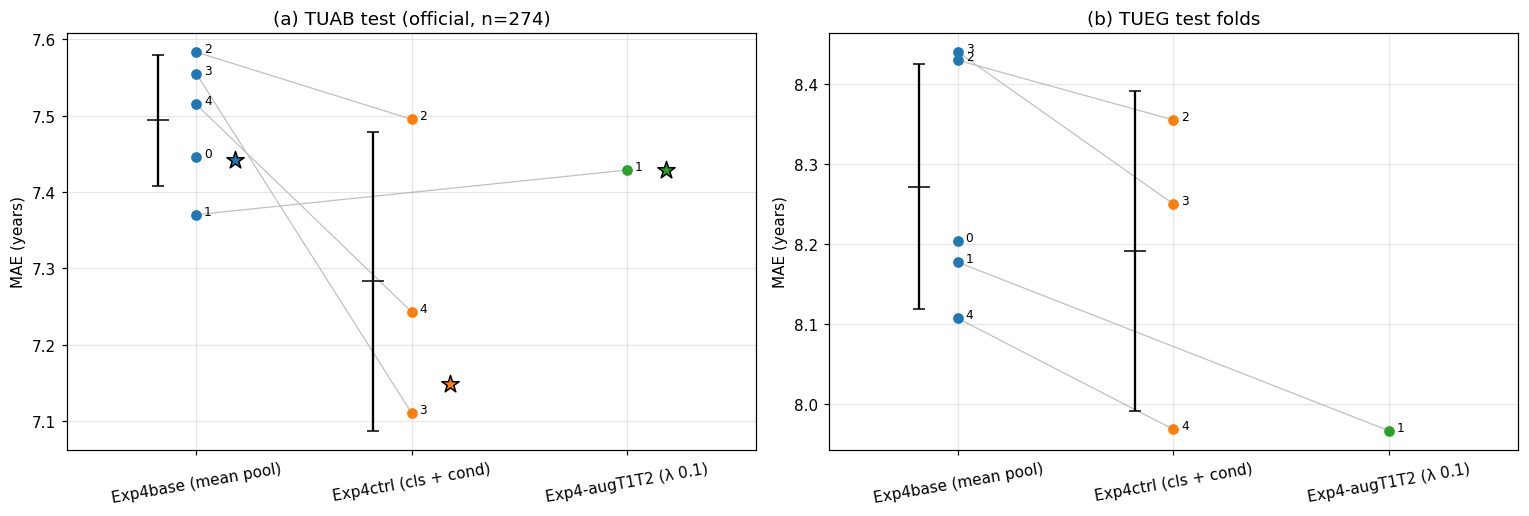

In [7]:
def fold_plot(ax, set_name, star=None):
    s = pf[(pf.set == set_name) & (pf.cohort == "all")]
    x = {e: i for i, e in enumerate(ORDER)}
    for k, g in s.groupby("fold"):
        g = g.set_index("exp").reindex(ORDER).dropna(subset=["MAE"])
        ax.plot([x[e] for e in g.index], g.MAE, "-", color="0.75", lw=0.8, zorder=1)
    for e in ORDER:
        g = s[s.exp == e]
        ax.scatter(np.full(len(g), x[e]), g.MAE, color=COLORS.get(e), zorder=2)
        for _, r in g.iterrows():
            ax.annotate(str(int(r.fold)), (x[e], r.MAE), xytext=(5, 0), textcoords="offset points", fontsize=8)
        if len(g) > 1:
            ax.errorbar(x[e] - 0.18, g.MAE.mean(), yerr=g.MAE.std(), fmt="_", color="k", capsize=4, ms=14)
        if star is not None and e in star:
            ax.scatter(x[e] + 0.18, star[e], marker="*", s=140, color=COLORS.get(e), edgecolor="k", zorder=3)
    ax.set_xticks(range(len(ORDER)), [EXPS.get(e, e) for e in ORDER], rotation=10)
    ax.set_xlim(-0.6, len(ORDER) - 0.4)
    ax.set_ylabel("MAE (years)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
fold_plot(axes[0], "TUAB test", star=t23["TUAB ens. median"].to_dict())
axes[0].set_title("TUAB test (official, n=274)")
fold_plot(axes[1], "TUEG test")
axes[1].set_title("TUEG test folds")
panel_labels(axes); assert_max_columns(fig); fig.tight_layout(); plt.show()

### Table 2.4. Paired fold differences against `cvbase`

For every other experiment and the folds it shares with `cvbase`: the per-fold difference
$\Delta_k = \mathrm{MAE}_k^{\mathrm{exp}} - \mathrm{MAE}_k^{\mathrm{cvbase}}$ (Eq. (2.1)), as mean ± sd over
the shared folds, and the number of folds on which the experiment is better ($\Delta_k<0$). Negative is better.

In [8]:
REF = "cvbase" if "cvbase" in ORDER else ORDER[0]
rows = []
base = pf[(pf.exp == REF) & (pf.cohort == "all")].set_index(["set", "fold"]).MAE
for e in ORDER:
    if e == REF:
        continue
    cur = pf[(pf.exp == e) & (pf.cohort == "all")].set_index(["set", "fold"]).MAE
    row = {"experiment": e}
    for s in SETS:
        if s not in cur.index.get_level_values(0):
            continue
        delta = (cur.xs(s) - base.xs(s)).dropna()
        row[f"{s} Δ"] = pm(delta)
        row[f"{s} wins"] = f"{int((delta < 0).sum())}/{len(delta)}"
    rows.append(row)
t24 = pd.DataFrame(rows).set_index("experiment") if rows else pd.DataFrame({"note": ["only one experiment scored"]})
numbered_table(t24, "2.4", "Paired fold differences")

,CV val Δ,CV val wins,CV test Δ,CV test wins,TUEG test Δ,TUEG test wins,TUAB test Δ,TUAB test wins
experiment,,,,,,,,
cvctrl,-0.09 ± 0.01,3/3,-0.13 ± 0.05,3/3,-0.13 ± 0.06,3/3,-0.27 ± 0.18,3/3
cvaug,-0.10,1/1,-0.22,1/1,-0.21,1/1,0.06,0/1


## 3. Correlation and agreement between models

On the official TUAB test every fold model predicts the same recordings, so any two models $a,b$ can be
compared recording by recording. With the errors (brain-age gaps) $e_{i}^{a} = \hat y_i^{a} - y_i$
(`cv_compare.py::pairwise`):

$$ r_{\mathrm{pred}}(a,b) = \operatorname{corr}_i\big(\hat y_i^{a}, \hat y_i^{b}\big) \tag{3.1} $$

$$ r_{\mathrm{err}}(a,b) = \operatorname{corr}_i\big(e_i^{a}, e_i^{b}\big) \tag{3.2} $$

$$ A_\tau(a,b) = \frac1n\sum_i \mathbb 1\big[\lvert \hat y_i^{a}-\hat y_i^{b}\rvert \le \tau\big] \tag{3.3} $$

$$ A_{\mathrm{sign}}(a,b) = \frac1n\sum_i \mathbb 1\big[\operatorname{sign} e_i^{a} = \operatorname{sign} e_i^{b}\big] \tag{3.4} $$

with Pearson's correlation, $\tau$ in years and $n$ the number of shared recordings. $r_{\mathrm{pred}}$ is
dominated by the true age (both models track it), so $r_{\mathrm{err}}$ is the informative one: it says
whether two models make the *same* mistakes. $A_\tau$ is the agreement rate, the share of recordings on
which the two predictions are within $\tau$ years of each other, and $A_{\mathrm{sign}}$ is the share on
which both call the brain older (or both younger) than the true age.

### Figure 3.1. Correlation between fold models on the TUAB test

Heatmaps over all scored fold models (`<exp>/f<fold>`), $n=274$ recordings. (a) $r_{\mathrm{pred}}$,
Eq. (3.1). (b) $r_{\mathrm{err}}$, Eq. (3.2). The black lines separate experiments.

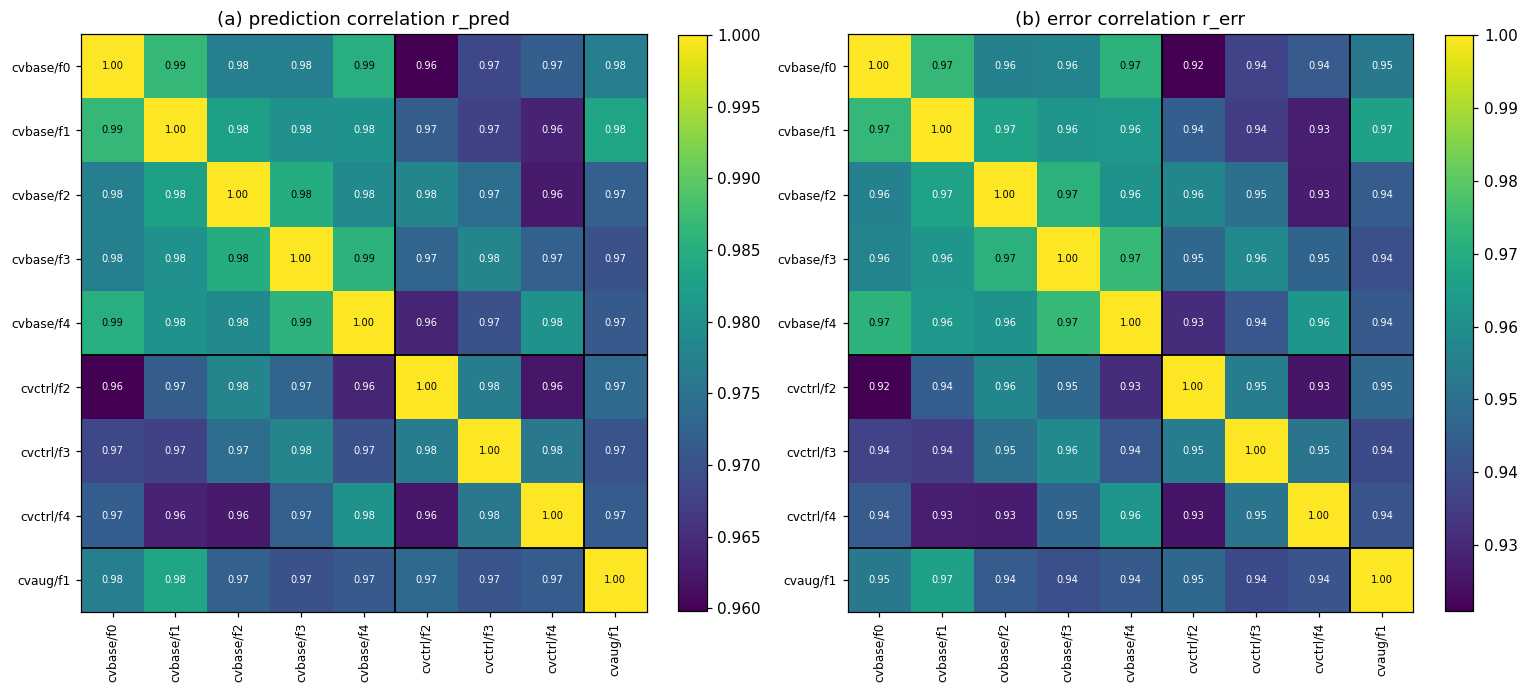

In [9]:
W = cc.model_matrix(d, "heldout")
W = W[[c for e in ORDER for c in W.columns if c.split("/")[0] == e]]
T = d[d.split == "heldout"].groupby("stem").true.first()
E = W.sub(T.loc[W.index], axis=0)

def heat(ax, M, title, vmin=None, fmt="{:.2f}"):
    im = ax.imshow(M.to_numpy(), vmin=vmin, vmax=1, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(M)), M.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(len(M)), M.index, fontsize=8)
    if len(M) <= 16:
        for i in range(len(M)):
            for j in range(len(M)):
                v = M.iat[i, j]
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=6.5,
                        color="w" if v < (vmin or 0) + 0.6 * (1 - (vmin or 0)) else "k")
    cuts = np.cumsum([sum(c.split("/")[0] == e for c in M.columns) for e in ORDER])[:-1] - 0.5
    for c in cuts:
        ax.axhline(c, color="k", lw=1.2); ax.axvline(c, color="k", lw=1.2)
    ax.grid(False); ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
heat(axes[0], W.corr(), "prediction correlation r_pred", vmin=float(W.corr().min().min()))
heat(axes[1], E.corr(), "error correlation r_err", vmin=float(E.corr().min().min()))
panel_labels(axes); assert_max_columns(fig); fig.tight_layout(); plt.show()

### Table 3.1. Within- vs. between-experiment pairs

Model pairs grouped by type: two fold models of the same experiment (*within*), or of two different
experiments (*between*). Mean over the pairs of $r_{\mathrm{pred}}$ (3.1), $r_{\mathrm{err}}$ (3.2),
$A_{2}$ and $A_{5}$ (3.3, $\tau = 2$ and $5$ years), $A_{\mathrm{sign}}$ (3.4) and $\lvert\Delta\mathrm{MAE}\rvert$
(years); TUAB test, $n=274$. If between-experiment pairs agree about as well as within-experiment pairs, the
choice of experiment matters less than the choice of training folds.

In [10]:
pw = cc.pairwise(W, T, taus=(2.0, 5.0))
ea_, eb_ = pw.a.str.split("/").str[0], pw.b.str.split("/").str[0]
pw["pair"] = np.where(ea_ == eb_, "within " + ea_, "between " + ea_ + " – " + eb_)
pw["|dMAE|"] = pw.dMAE.abs()
t31 = pw.groupby("pair", sort=False).agg(pairs=("a", "size"), r_pred=("r_pred", "mean"), r_err=("r_err", "mean"),
                                          A_2y=("agree_2y", "mean"), A_5y=("agree_5y", "mean"),
                                          A_sign=("sign_agree", "mean"), abs_dMAE=("|dMAE|", "mean"))
numbered_table(t31, "3.1", "Within vs between experiments", precision=3)

,pairs,r_pred,r_err,A_2y,A_5y,A_sign,abs_dMAE
pair,,,,,,,
within cvbase,10,0.982,0.966,0.668,0.934,0.931,0.107
between cvbase – cvctrl,15,0.970,0.942,0.538,0.876,0.891,0.234
between cvbase – cvaug,5,0.975,0.949,0.547,0.889,0.902,0.089
within cvctrl,3,0.972,0.944,0.569,0.903,0.903,0.257
between cvctrl – cvaug,3,0.972,0.943,0.546,0.894,0.895,0.190


### Figure 3.2. Agreement rate

(a) $A_5$ (Eq. (3.3), $\tau=5$ years) between every pair of fold models on the TUAB test, $n=274$.
(b) $A_\tau$ as a function of $\tau$ (0–10 years), averaged over the pairs of each type of Table 3.1.

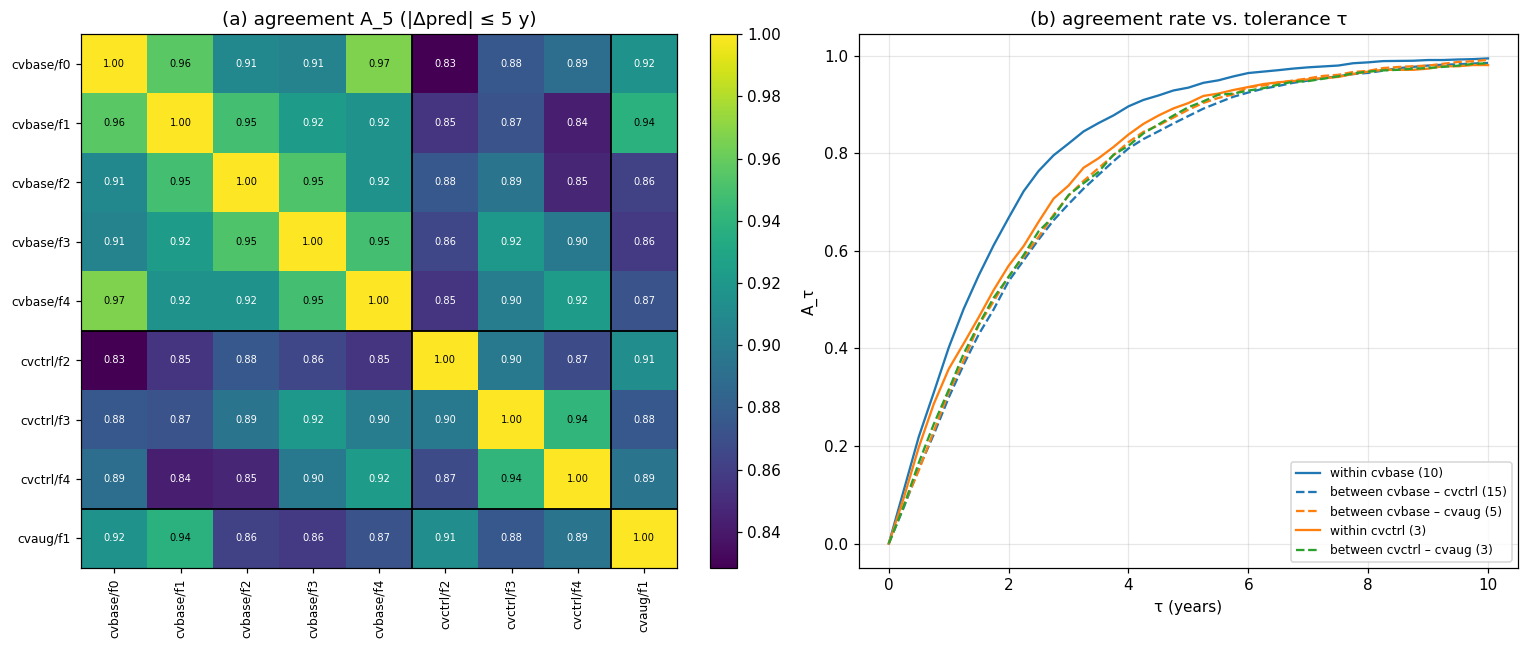

In [11]:
taus = np.linspace(0, 10, 41)
cols = list(W.columns)
A5 = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
for _, r in pw.iterrows():
    A5.loc[r.a, r.b] = A5.loc[r.b, r.a] = r.agree_5y
fig, axes = plt.subplots(1, 2, figsize=(14, 6.0))
heat(axes[0], A5, "agreement A_5 (|Δpred| ≤ 5 y)", vmin=float(A5.min().min()))
for pair, g in pw.groupby("pair", sort=False):
    curve = [np.mean([cc.agreement(W[a], W[b], tau) for a, b in zip(g.a, g.b)]) for tau in taus]
    ls = "-" if pair.startswith("within") else "--"
    color = COLORS.get(pair.split()[1]) if pair.startswith("within") else None
    axes[1].plot(taus, curve, ls, color=color, label=f"{pair} ({len(g)})")
axes[1].set_xlabel("τ (years)"); axes[1].set_ylabel("A_τ"); axes[1].legend(fontsize=8)
axes[1].set_title("agreement rate vs. tolerance τ")
panel_labels(axes); assert_max_columns(fig); fig.tight_layout(); plt.show()

### Table 3.2. Between experiments: ensembles and out-of-fold

Each experiment reduced to one prediction per recording: the median ensemble (Eq. (2.6)) on the TUAB test,
and the out-of-fold prediction on the TUEG test folds that both experiments of the pair have scored (named in
the set label; a pair without a shared fold has no TUEG row). Per pair $(a,b)$
and set: $n$; $r_{\mathrm{pred}}$, $r_{\mathrm{err}}$, $A_2$, $A_5$, $A_{\mathrm{sign}}$ (Eqs. (3.1)–(3.4));
and $\Delta\mathrm{MAE} = \mathrm{MAE}_a - \mathrm{MAE}_b$ with the 95% percentile interval of the paired
bootstrap over recordings (2,000 resamples, `cv_compare.py::bootstrap_delta_mae`),

$$ \Delta^{*}_{r} = \frac1n\sum_i\big(\lvert e^{a}_{i_r}\rvert - \lvert e^{b}_{i_r}\rvert\big), \quad
   i_r \sim \mathrm{Unif}\{1..n\}^n, \qquad P(a\ \mathrm{better}) = \frac1R\sum_r \mathbb 1[\Delta^{*}_r < 0]. \tag{3.5} $$

The bootstrap treats the recordings as independent and the models as fixed; it ignores the fold-to-fold
variation of Table 2.1.

In [12]:
oof_tueg = oof[oof.source == "TUEG"]

def shared_folds(*exps):
    return sorted(set.intersection(*(set(oof_tueg[oof_tueg.exp == e].fold) for e in exps)))

def pair_frames(a, b):
    folds = shared_folds(a, b)
    out = {"TUAB test (median ens.)": ens[ens.exp.isin([a, b])]}
    if folds:
        out[f"TUEG test (out-of-fold, folds {','.join(map(str, folds))})"] = \
            oof_tueg[oof_tueg.exp.isin([a, b]) & oof_tueg.fold.isin(folds)]
    return out

def between(pairs_):
    rows = []
    for a, b in pairs_:
        for set_name, frame in pair_frames(a, b).items():
            Wx = frame.pivot_table(index="stem", columns="exp", values="pred")[[a, b]].dropna()
            t_ = frame.groupby("stem").true.first().loc[Wx.index]
            r = cc.pairwise(Wx, t_, taus=(2.0, 5.0)).iloc[0]
            bs = cc.bootstrap_delta_mae(Wx[a] - t_, Wx[b] - t_, n_boot=2000, seed=0)
            rows.append({"set": set_name, "a": a, "b": b, "n": len(Wx), "r_pred": r.r_pred, "r_err": r.r_err,
                         "A_2y": r.agree_2y, "A_5y": r.agree_5y, "A_sign": r.sign_agree, "ΔMAE": bs["dMAE"],
                         "95% CI": f"[{bs['lo']:+.2f}, {bs['hi']:+.2f}]", "P(a better)": bs["p_a_better"]})
    return pd.DataFrame(rows)

pairs = [(a, b) for i, a in enumerate(ORDER) for b in ORDER[i + 1:]]
t32 = between(pairs)
numbered_table(t32.set_index(["set", "a", "b"]) if len(t32) else pd.DataFrame({"note": ["one experiment"]}),
               "3.2", "Between experiments", precision=3)

,,,n,r_pred,r_err,A_2y,A_5y,A_sign,ΔMAE,95% CI,P(a better)
set,a,b,,,,,,,,,
TUAB test (median ens.),cvbase,cvctrl,274,0.984,0.969,0.657,0.942,0.909,0.294,"[+0.02, +0.58]",0.017
"TUEG test (out-of-fold, folds 2,3,4)",cvbase,cvctrl,16221,0.964,0.947,0.513,0.872,0.903,0.135,"[+0.08, +0.18]",0.000
TUAB test (median ens.),cvbase,cvaug,274,0.982,0.963,0.577,0.934,0.901,0.013,"[-0.30, +0.32]",0.463
"TUEG test (out-of-fold, folds 1)",cvbase,cvaug,5297,0.969,0.953,0.525,0.886,0.893,0.211,"[+0.12, +0.29]",0.000
TUAB test (median ens.),cvctrl,cvaug,274,0.979,0.957,0.595,0.920,0.905,-0.281,"[-0.59, +0.02]",0.965


### Figure 3.3. Errors of one experiment against another

For each pair of experiments, a row of two panels: the error $e^{b}_i$ against $e^{a}_i$ (years,
Eq. (3.2)) of (left) the median ensembles on the TUAB test ($n=274$) and (right) the out-of-fold
predictions on the TUEG test folds both have scored (density, log colour scale). The diagonal is equal error; the
shaded band is $\lvert \hat y^a - \hat y^b\rvert \le 5$ years ($A_5$, Eq. (3.3)). Panel titles give
$r_{\mathrm{err}}$.

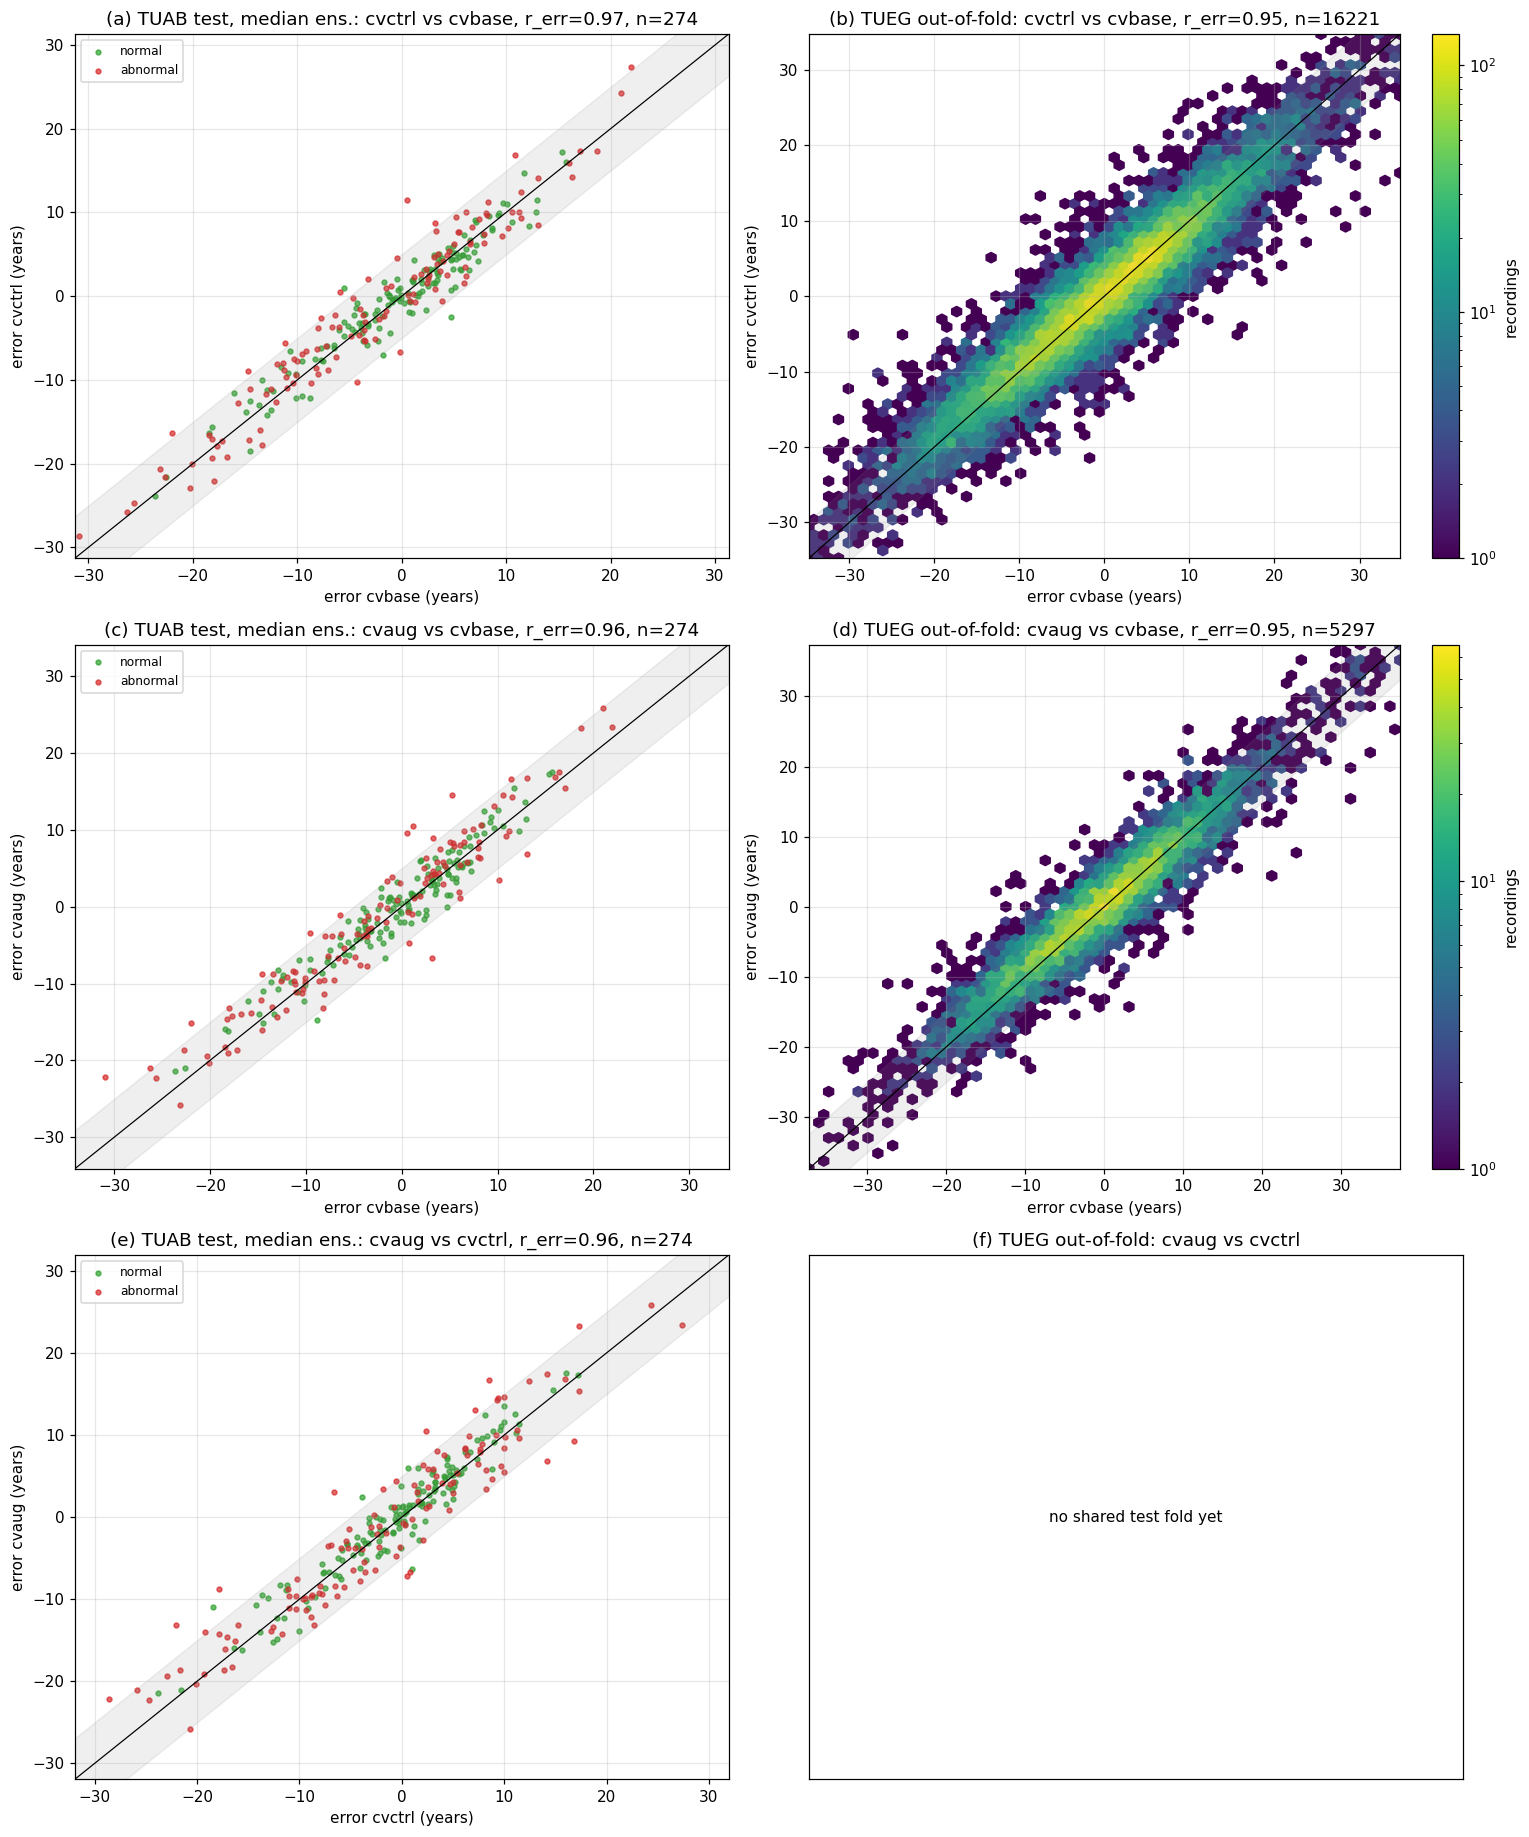

In [13]:
if pairs:
    fig, axes = plt.subplots(len(pairs), 2, figsize=(14, 5.6 * len(pairs)), squeeze=False)
    for row, (a, b) in zip(axes, pairs):
        folds = shared_folds(a, b)
        if not folds:
            row[1].text(0.5, 0.5, "no shared test fold yet", ha="center", va="center", transform=row[1].transAxes)
            row[1].set_xticks([]); row[1].set_yticks([]); row[1].grid(False)
            row[1].set_title(f"TUEG out-of-fold: {b} vs {a}")
        for ax, frame, kind in ((row[0], ens, "TUAB test, median ens."),
                                (row[1], oof_tueg[oof_tueg.fold.isin(folds)], "TUEG out-of-fold"))[:2 if folds else 1]:
            Wx = frame.pivot_table(index="stem", columns="exp", values="err")[[a, b]].dropna()
            lim = np.percentile(np.abs(Wx.to_numpy()), 99.5)
            if kind.startswith("TUAB"):
                st = Wx.index.map(status)
                for s_, c_ in STATUS_COLORS.items():
                    m_ = st == s_
                    if m_.any():
                        ax.scatter(Wx[a][m_], Wx[b][m_], s=10, alpha=0.7, color=c_, label=s_)
                ax.legend(fontsize=8)
            else:
                hb = ax.hexbin(Wx[a], Wx[b], gridsize=60, bins="log", cmap="viridis",
                               extent=(-lim, lim, -lim, lim), mincnt=1)
                plt.colorbar(hb, ax=ax, fraction=0.046, label="recordings")
            ax.plot([-lim, lim], [-lim, lim], "k-", lw=0.8)
            ax.fill_between([-lim, lim], [-lim - 5, lim - 5], [-lim + 5, lim + 5], color="0.5", alpha=0.12)
            ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
            ax.set_xlabel(f"error {a} (years)"); ax.set_ylabel(f"error {b} (years)")
            ax.set_title(f"{kind}: {b} vs {a}, r_err={np.corrcoef(Wx[a], Wx[b])[0, 1]:.2f}, n={len(Wx)}")
    panel_labels(axes); assert_max_columns(fig); fig.tight_layout(); plt.show()
else:
    print("one experiment scored: nothing to pair")

## 4. Predicted vs. true age by data source and pathology group

Per experiment, a figure of four panels (Figures 4.1 to 4.*K*, one per experiment, in the order of Table 1.1):

* (a) official TUAB test, median ensemble (Eq. (2.6)), $n=274$;
* (b) TUAB train/val recordings, out-of-fold (Eq. (2.7)); these patients are in the CV pool, unlike (a);
* (c) TUEG recordings, out-of-fold (density);
* (d) mean error $\pm$ sd per true-age decade for the three sets.

Colours are the recording's status (normal / abnormal / not available). Lines in (a)–(c) are the per-status
OLS fit (`np.polyfit`)

$$ \hat y_i = \beta_s\,y_i + \alpha_s + \varepsilon_i, \qquad i \in s, \tag{4.1} $$

against the identity $\hat y = y$; a slope $\beta_s<1$ is the usual regression to the mean (old brains
predicted too young, young too old). Ages in years.

### Figure 4.1. Predicted vs. true age, cvbase

Exp4base (mean pool); 5 fold models in the ensemble (a), 5 test folds in (b)–(c).

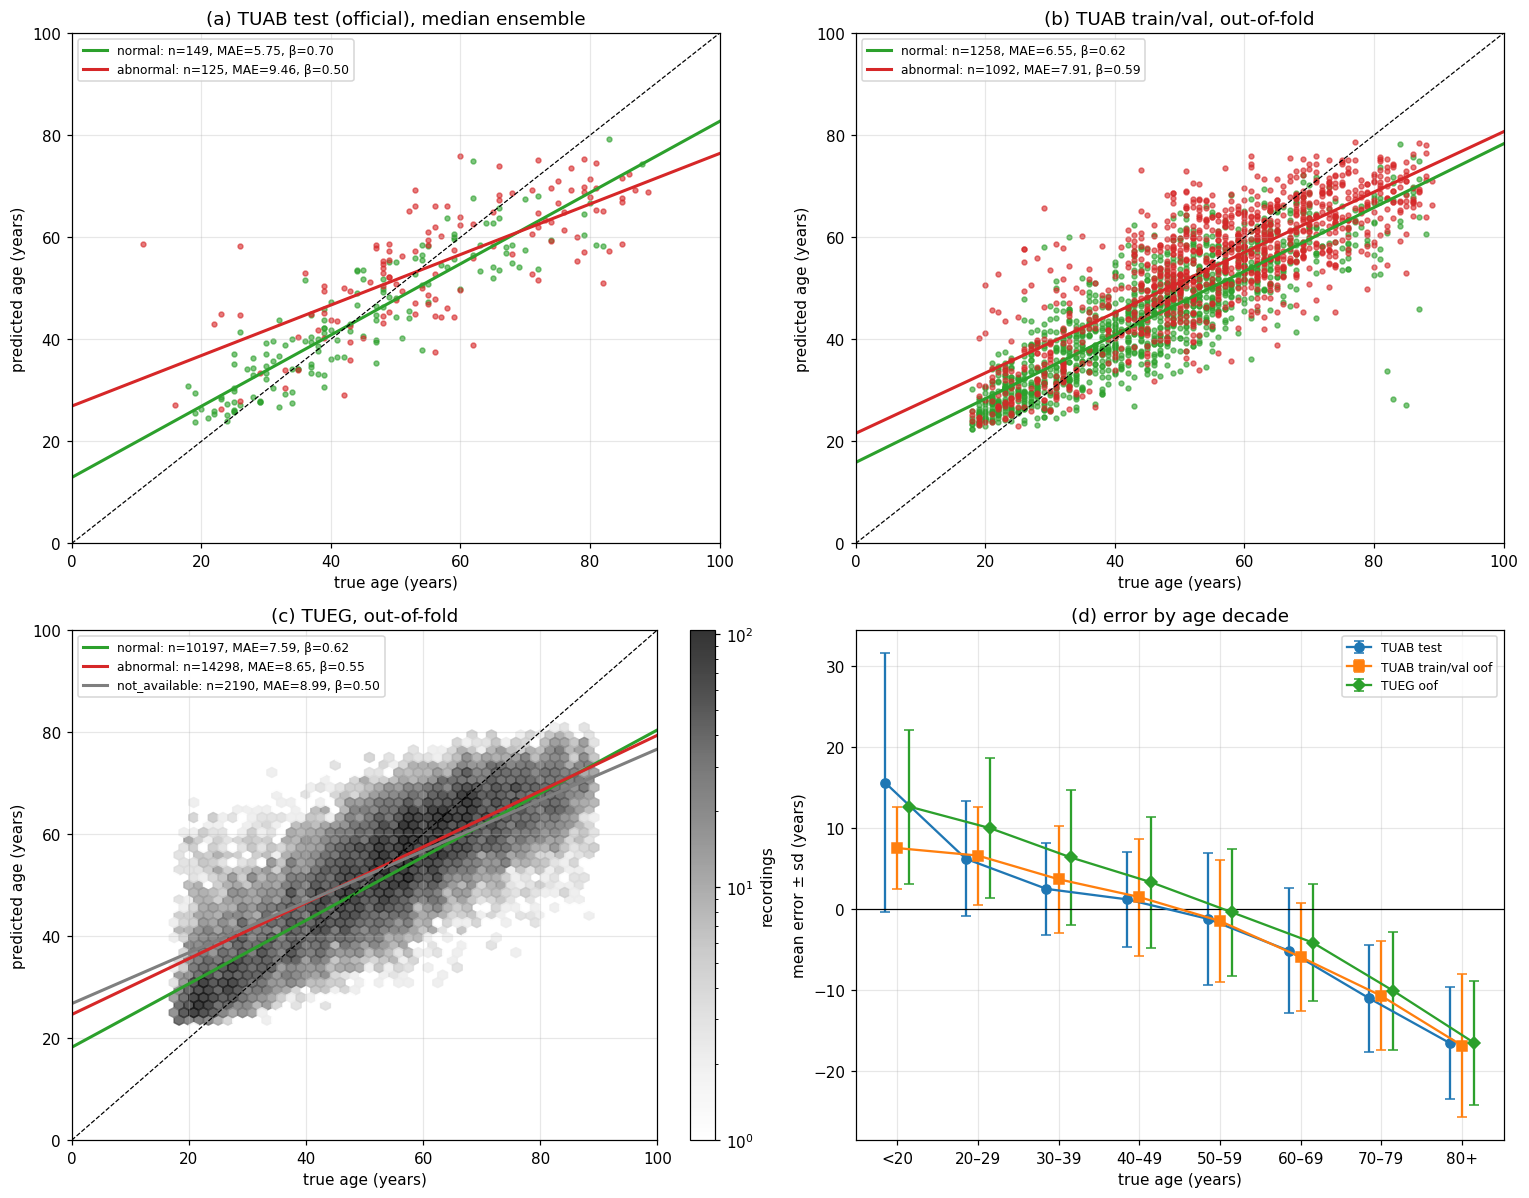

### Figure 4.2. Predicted vs. true age, cvctrl

Exp4ctrl (cls + cond); 3 fold models in the ensemble (a), 3 test folds in (b)–(c).

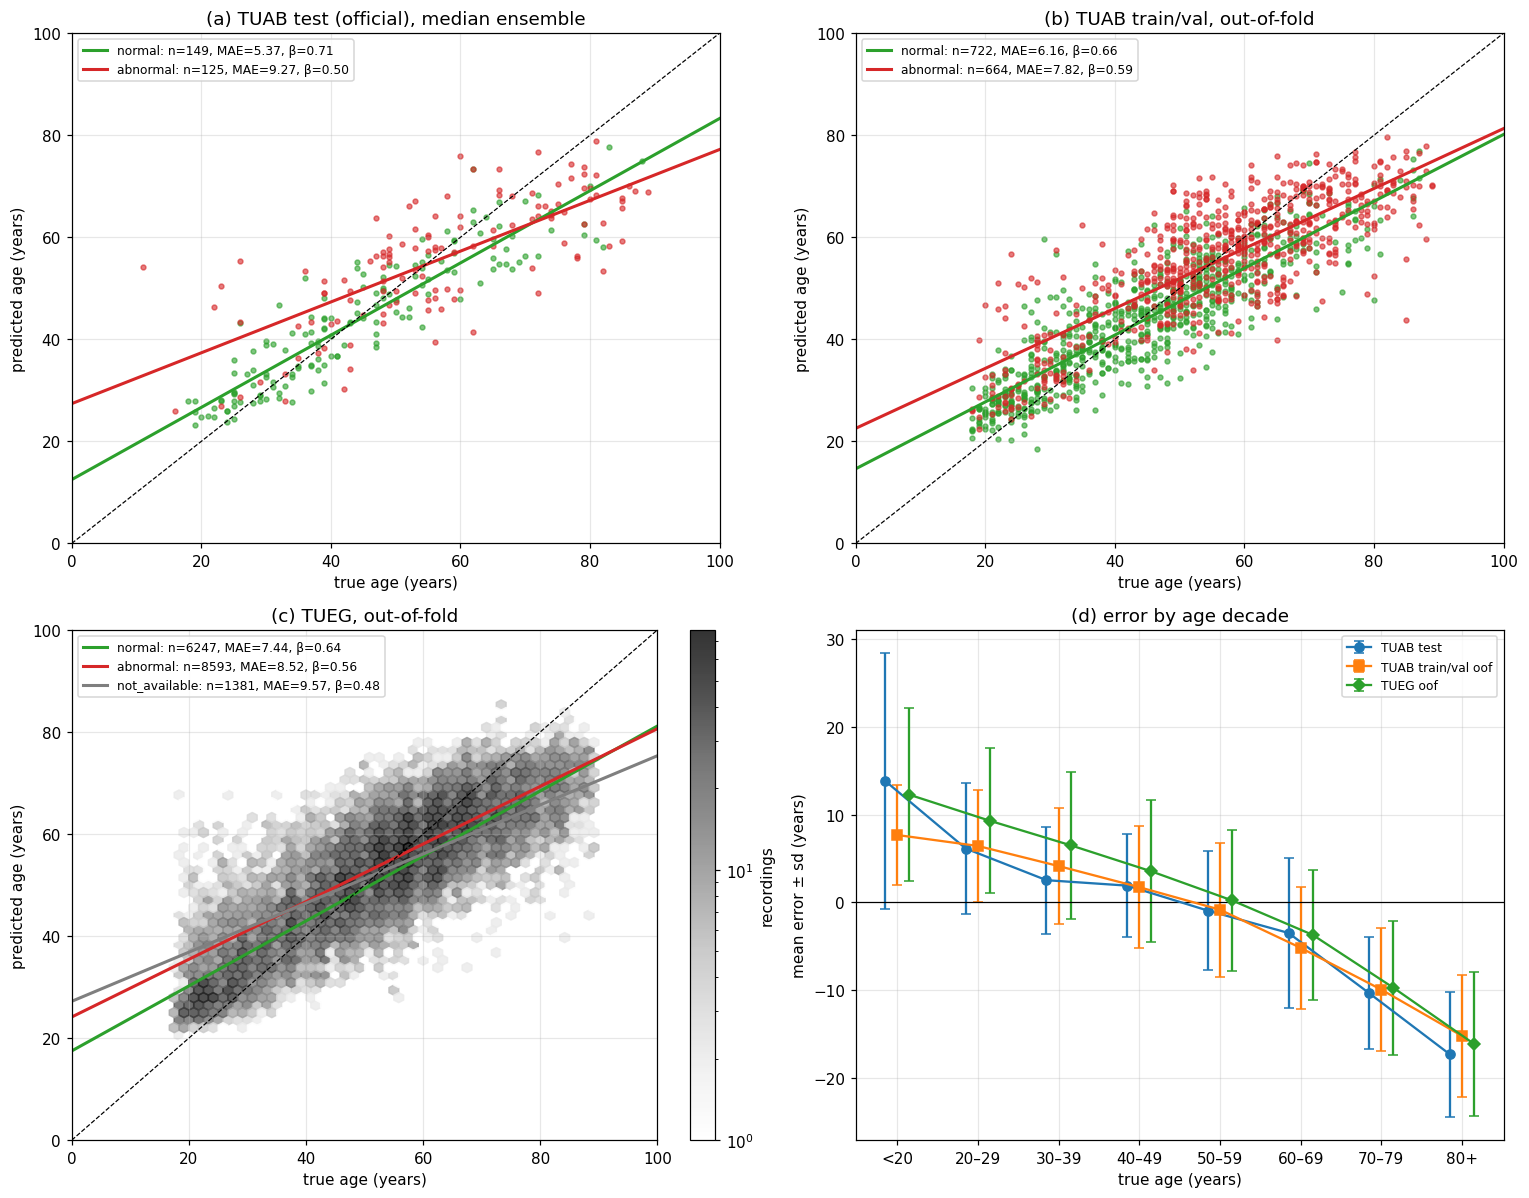

### Figure 4.3. Predicted vs. true age, cvaug

Exp4-augT1T2 (λ 0.1); 1 fold models in the ensemble (a), 1 test folds in (b)–(c).

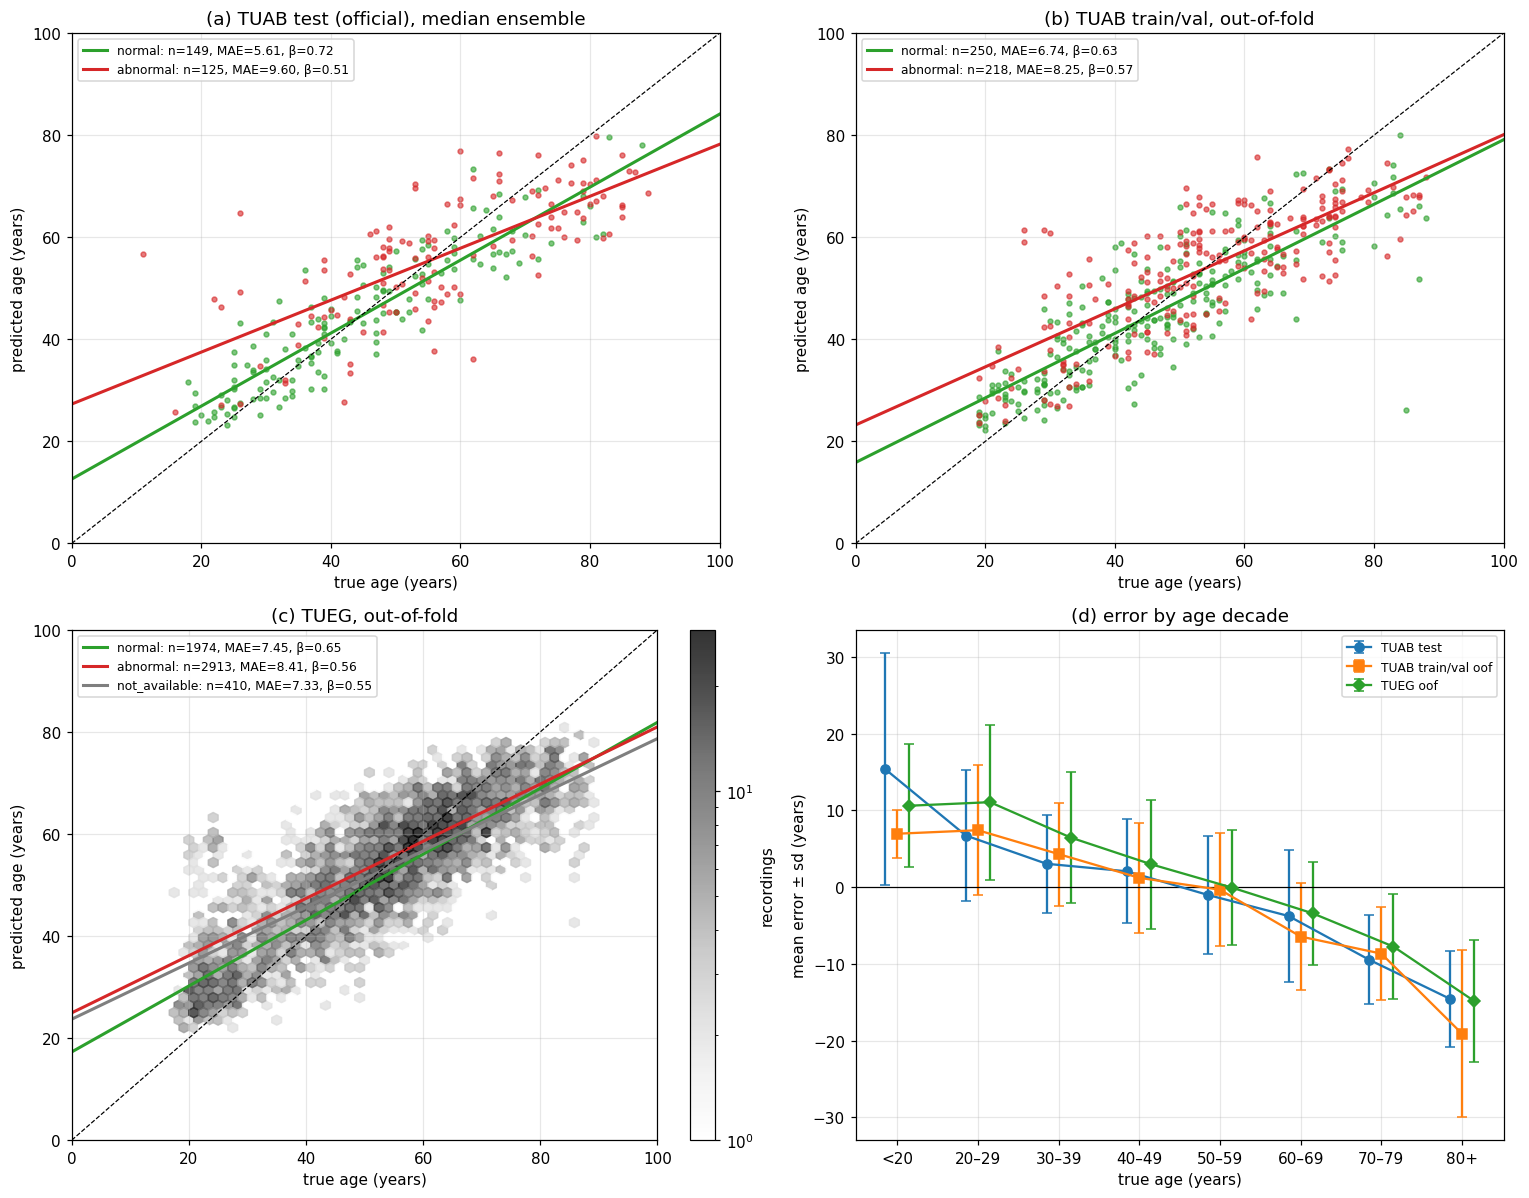

In [14]:
def scatter_status(ax, frame, title, density=False):
    lim = (0, max(100, frame.true.max() + 2))
    if density:
        hb = ax.hexbin(frame.true, frame.pred, gridsize=60, bins="log", cmap="Greys", mincnt=1,
                       extent=(*lim, *lim), alpha=0.8)
        plt.colorbar(hb, ax=ax, fraction=0.046, label="recordings")
    for s_, c_ in STATUS_COLORS.items():
        g = frame[frame.status == s_]
        if len(g) < 5:
            continue
        if not density:
            ax.scatter(g.true, g.pred, s=10, alpha=0.6, color=c_)
        beta, alpha = np.polyfit(g.true, g.pred, 1)
        m = cc.metrics(g.pred, g.true)
        ax.plot(lim, np.polyval([beta, alpha], lim), color=c_, lw=2,
                label=f"{s_}: n={m['n']}, MAE={m['MAE']:.2f}, β={beta:.2f}")
    ax.plot(lim, lim, "k--", lw=0.8)
    ax.set_xlim(*lim); ax.set_ylim(*lim)
    ax.set_xlabel("true age (years)"); ax.set_ylabel("predicted age (years)")
    ax.legend(fontsize=8, loc="upper left"); ax.set_title(title)

def by_decade(ax, frames):
    for (name, frame), mk in zip(frames.items(), "osD"):
        b = pd.cut(frame.true, AGE_EDGES, right=False, labels=AGE_LABELS)
        g = frame.groupby(b, observed=True).err.agg(["mean", "std", "size"])
        g = g[g["size"] >= 5]
        x = [AGE_LABELS.index(i) for i in g.index]
        ax.errorbar(np.array(x) + {"o": -0.15, "s": 0, "D": 0.15}[mk], g["mean"], yerr=g["std"], fmt=mk + "-",
                    capsize=3, label=name)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(range(len(AGE_LABELS)), AGE_LABELS)
    ax.set_xlabel("true age (years)"); ax.set_ylabel("mean error ± sd (years)")
    ax.legend(fontsize=8); ax.set_title("error by age decade")

oof = oof.assign(status=lambda x: x.stem.map(status))
for n_fig, e in enumerate(ORDER, start=1):
    figure_heading(f"4.{n_fig}", f"Predicted vs. true age, {e}",
                   f"{EXPS.get(e, e)}; {ens[ens.exp == e].n_models.max()} fold models in the ensemble (a), "
                   f"{oof[oof.exp == e].fold.nunique()} test folds in (b)–(c).")
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    ea = ens[ens.exp == e]
    ob = oof[(oof.exp == e) & (oof.source == "TUAB")]
    ot = oof[(oof.exp == e) & (oof.source == "TUEG")]
    scatter_status(axes[0, 0], ea, "TUAB test (official), median ensemble")
    scatter_status(axes[0, 1], ob, "TUAB train/val, out-of-fold")
    scatter_status(axes[1, 0], ot, "TUEG, out-of-fold", density=True)
    by_decade(axes[1, 1], {"TUAB test": ea, "TUAB train/val oof": ob, "TUEG oof": ot})
    panel_labels(axes); assert_max_columns(fig); fig.tight_layout(); plt.show()

### Pathology groups

The pathology groups are the 14 multi-hot flags of `conditions_v1.npz` (`dataset_maker/make_condition_features.py`,
from the NEDC clinical sheet); a recording can be in several groups, and `healthy_or_not_available` means no
diagnosis was found. The brain-age gap of recording $i$ is

$$ \delta_i = \hat y_i - y_i \tag{4.2} $$

(out-of-fold prediction, years). Because $\delta$ depends on age through the regression to the mean
(Eq. (4.1)), groups with different age mixes are compared on the **bias-corrected** gap

$$ \delta'_i = \delta_i - (\hat b\, y_i + \hat a), \qquad (\hat b,\hat a) = \operatorname*{arg\,min}_{b,a}\sum_{j\in R}(\delta_j - b\,y_j - a)^2 \tag{4.3} $$

with the reference set $R$ = out-of-fold recordings that are *normal* and *healthy_or_not_available*
(`cv_compare.py::bias_correct`), fitted per experiment. $\delta'$ is about 0 on average in $R$; a
positive group mean means that group's brains look older than healthy brains of the same age.

**Caveat: condition inputs.** `cvctrl` and `cvaug` receive the status and pathology vector itself as an input
to the head, so they can learn a per-group age offset from the label rather than from the EEG. Their
per-group gaps (Figure 5.2(b), Table 5.2) therefore mix EEG evidence with the label they were given, and are
not a brain-age biomarker in the usual sense. The per-group predicted-vs-true figure (Figure 4.4) uses `cvbase`, which sees
only the EEG (the dots of the TUEG panels in Figures 4.1–4.3 are the same recordings for every experiment).

In [15]:
oof_all = oof.copy()
groups = [g for g in patho.columns if patho.loc[oof_all.stem.unique(), g].sum() >= MIN_GROUP]
# the gap per pathology group is read from a model that never sees the diagnosis: cvbase has no
# condition input (cvctrl / cvaug get the status + pathology vector in the head)
enough = [e for e in ORDER if oof_all[oof_all.exp == e].fold.nunique() >= 3] or ORDER
REF_EXP = "cvbase" if "cvbase" in ORDER else t23.loc[enough, "TUEG oof MAE"].idxmin()
for e in ORDER:
    o = oof_all.exp == e
    ref = o & (oof_all.status == "normal") & oof_all.stem.map(patho["healthy_or_not_available"])
    oof_all.loc[o, "bag_c"] = cc.bias_correct(oof_all.loc[o, "err"], oof_all.loc[o, "true"],
                                              oof_all.loc[ref, "err"], oof_all.loc[ref, "true"])
print(f"{len(groups)} pathology groups with at least {MIN_GROUP} out-of-fold recordings; "
      f"Figure 4.{len(ORDER) + 1} uses {REF_EXP} (the model without condition inputs)")

14 pathology groups with at least 30 out-of-fold recordings; Figure 4.4 uses cvbase (the model without condition inputs)


### Figure 4.4. Predicted vs. true age per pathology group, cvbase

One panel per pathology group with at least 30 out-of-fold recordings (TUAB train/val and TUEG pooled); the grey density is the reference set R of Eq. (4.3) (normal and healthy), the dots the group's recordings, the line the group's OLS fit (Eq. (4.1)). Titles give n, MAE (Eq. (2.1)) and the mean bias-corrected gap δ' (Eq. (4.3)) ± its 95% interval (Eq. (5.2)). Years.

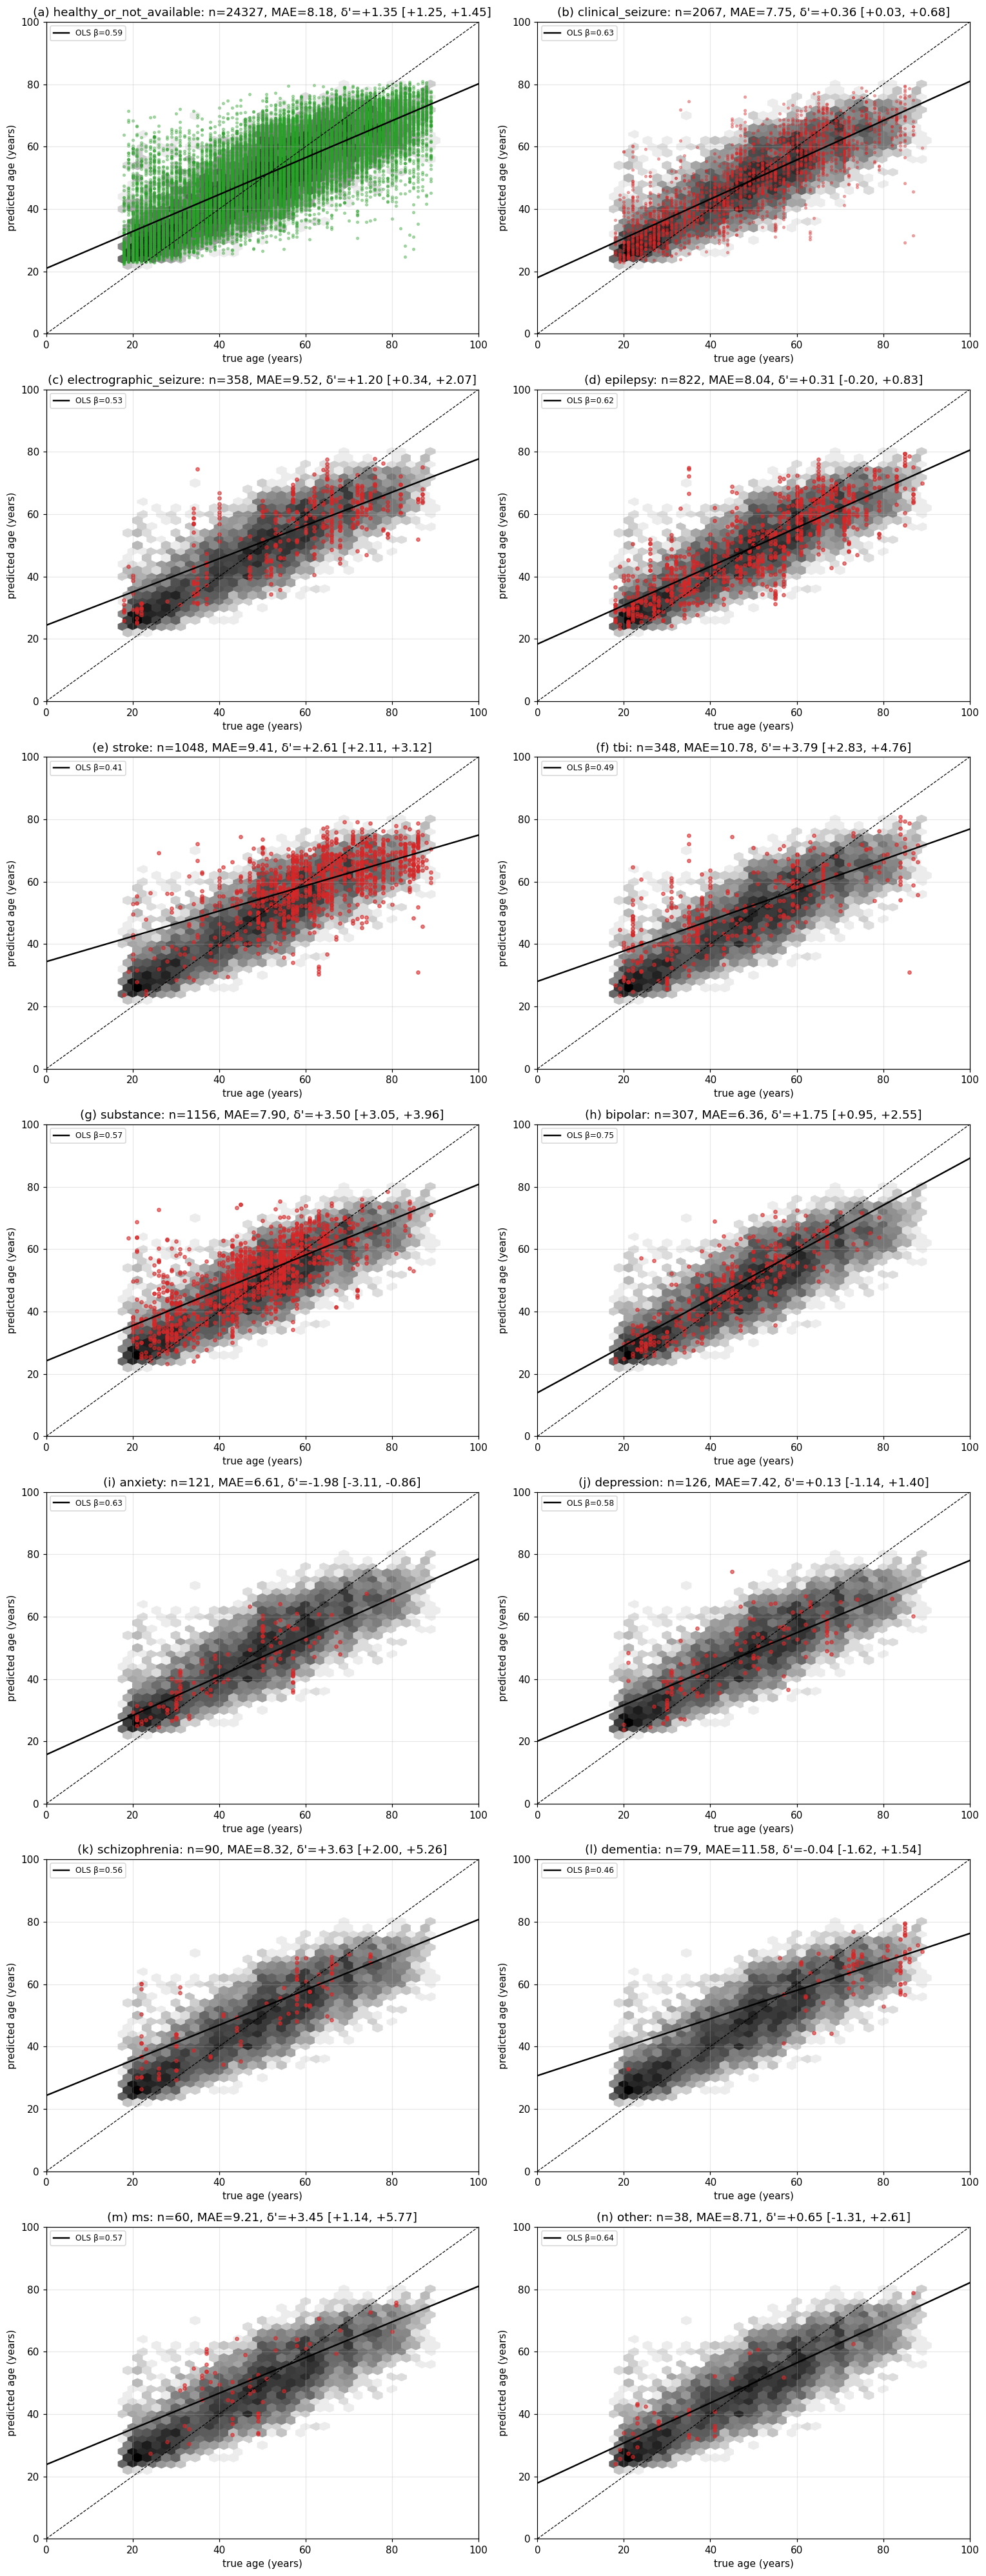

In [16]:
figure_heading(f"4.{len(ORDER) + 1}", f"Predicted vs. true age per pathology group, {REF_EXP}",
               "One panel per pathology group with at least 30 out-of-fold recordings (TUAB train/val and TUEG pooled); "
               "the grey density is the reference set R of Eq. (4.3) (normal and healthy), the dots the group's "
               "recordings, the line the group's OLS fit (Eq. (4.1)). Titles give n, MAE (Eq. (2.1)) and the mean "
               "bias-corrected gap δ' (Eq. (4.3)) ± its 95% interval (Eq. (5.2)). Years.")
o = oof_all[oof_all.exp == REF_EXP]
refm = (o.status == "normal") & o.stem.map(patho["healthy_or_not_available"])
rows = int(np.ceil(len(groups) / 2))
fig, axes = plt.subplots(rows, 2, figsize=(14, 5.2 * rows), squeeze=False)
lim = (0, 100)
for ax, g in zip(axes.ravel(), groups):
    m = o.stem.map(patho[g]).to_numpy()
    sub = o[m]
    ax.hexbin(o[refm].true, o[refm].pred, gridsize=45, bins="log", cmap="Greys", mincnt=1, extent=(*lim, *lim))
    col = "tab:green" if g == "healthy_or_not_available" else "tab:red"
    ax.scatter(sub.true, sub.pred, s=6 if len(sub) > 2000 else 12, alpha=0.35 if len(sub) > 2000 else 0.6, color=col)
    beta, alpha = np.polyfit(sub.true, sub.pred, 1)
    ax.plot(lim, np.polyval([beta, alpha], lim), color="k", lw=1.6, label=f"OLS β={beta:.2f}")
    ax.plot(lim, lim, "k--", lw=0.8)
    mm, ci = cc.metrics(sub.pred, sub.true), cc.mean_ci(sub.bag_c)
    ax.set_xlim(*lim); ax.set_ylim(*lim); ax.legend(fontsize=8, loc="upper left")
    ax.set_title(f"{g}: n={mm['n']}, MAE={mm['MAE']:.2f}, δ'={ci['mean']:+.2f} [{ci['lo']:+.2f}, {ci['hi']:+.2f}]",
                 fontsize=9)
    ax.set_xlabel("true age (years)"); ax.set_ylabel("predicted age (years)")
for ax in axes.ravel()[len(groups):]:
    ax.remove()
panel_labels([a for a in axes.ravel()[:len(groups)]]); assert_max_columns(fig); fig.tight_layout(); plt.show()

## 5. Error bars by cohort, pathology group and age

Two kinds of error bar are used. Across **fold models** (TUAB test; each fold model scores the same
recordings) and across **test folds** (TUEG; each fold scores different recordings), the bar is the sample sd
of the per-model MAE,

$$ \overline{\mathrm{MAE}}_c \pm s_c, \qquad s_c = \Big(\frac{1}{K-1}\sum_k(\mathrm{MAE}_{c,k}-\overline{\mathrm{MAE}}_c)^2\Big)^{1/2}, \tag{5.1} $$

for cohort $c$ (Eq. (2.5) restricted to $c$). For the **mean brain-age gap** of a group of $n$ recordings
the bar is the normal-approximation 95% interval of the mean (`cv_compare.py::mean_ci`),

$$ \bar\delta' \pm 1.96\,\frac{s_{\delta'}}{\sqrt n}. \tag{5.2} $$

### Figure 5.1. MAE per status cohort

Bars: $\overline{\mathrm{MAE}}_c \pm s_c$ (Eq. (5.1)) per experiment and cohort. (a) Official TUAB test,
over fold models; the cross marks the median ensemble (Eq. (2.6)). (b) TUEG test folds, over folds; cohorts
normal / abnormal / not available (no report label). Years; the numbers are in Table 5.1.

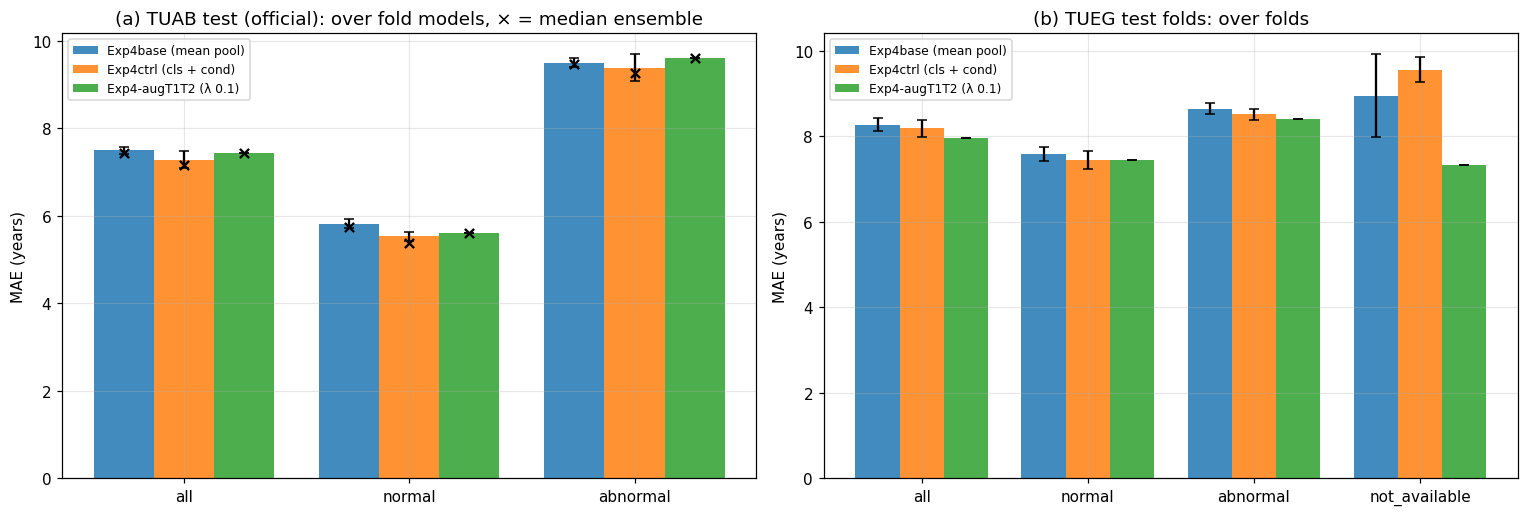

In [17]:
def grouped_bars(ax, frame, cohorts, star=None):
    w = 0.8 / len(ORDER)
    for j, e in enumerate(ORDER):
        g = frame[frame.exp == e].groupby("cohort").MAE.agg(["mean", "std"]).reindex(cohorts)
        x = np.arange(len(cohorts)) + (j - (len(ORDER) - 1) / 2) * w
        ax.bar(x, g["mean"], w, yerr=g["std"].fillna(0), capsize=3, color=COLORS.get(e), alpha=0.85,
               label=EXPS.get(e, e))
        if star is not None:
            ax.scatter(x, [star.get((e, c), np.nan) for c in cohorts], marker="x", color="k", zorder=3)
    ax.set_xticks(range(len(cohorts)), cohorts); ax.set_ylabel("MAE (years)"); ax.legend(fontsize=8)

ens_c = {(e, c): cc.metrics(g.pred, g.true)["MAE"] for e in ORDER
         for c, g in [("all", ens[ens.exp == e])] + list(ens[ens.exp == e].groupby("status"))}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
grouped_bars(axes[0], pf[pf.set == "TUAB test"], ["all", "normal", "abnormal"], star=ens_c)
axes[0].set_title("TUAB test (official): over fold models, × = median ensemble")
grouped_bars(axes[1], pf[pf.set == "TUEG test"], ["all", "normal", "abnormal", "not_available"])
axes[1].set_title("TUEG test folds: over folds")
panel_labels(axes); assert_max_columns(fig); fig.tight_layout(); plt.show()

### Table 5.1. MAE per status cohort

The values of Figure 5.1: $\overline{\mathrm{MAE}}_c \pm s_c$ (Eq. (5.1)) and the mean number of
recordings per fold model, per set and cohort; TUAB test also the median ensemble (Eq. (2.6)). Years.

In [18]:
rows = []
for s_name, cohorts in (("TUAB test", ["all", "normal", "abnormal"]), ("TUEG test", ["all", "normal", "abnormal", "not_available"])):
    for c in cohorts:
        row = {"set": s_name, "cohort": c}
        for e in ORDER:
            g = pf[(pf.set == s_name) & (pf.exp == e) & (pf.cohort == c)]
            row["n / fold"] = int(round(g.n.mean())) if len(g) else row.get("n / fold")
            row[e] = pm(g.MAE) if len(g) else "–"
            if s_name == "TUAB test":
                row[f"{e} ens."] = ens_c.get((e, c))
        rows.append(row)
numbered_table(pd.DataFrame(rows).set_index(["set", "cohort"]), "5.1", "MAE per status cohort")

### Figure 5.2. Pathology groups

Out-of-fold recordings (TUAB train/val and TUEG pooled) of the test folds that **every** experiment has
scored (so they are compared on the same recordings; their count is in the labels; an experiment without a
fold in common with the others is left out, as printed above the figure), one bar group per
pathology group with at least 30 recordings. (a) MAE per test fold, mean ± sd over folds (Eq. (5.1)). (b) Mean bias-corrected brain-age gap
$\bar\delta'$ (Eq. (4.3)) ± its 95% interval (Eq. (5.2)), per experiment; the dashed line is the reference set
$R$ (0 by construction). Years; the numbers are in Table 5.2. Only the `cvbase` gaps are EEG-only; the
condition-input models know each recording's group (see the caveat in Section 4).

Figure 5.2 / Table 5.2: cvbase, cvctrl on test folds [2, 3, 4]; left out (no shared fold): cvaug


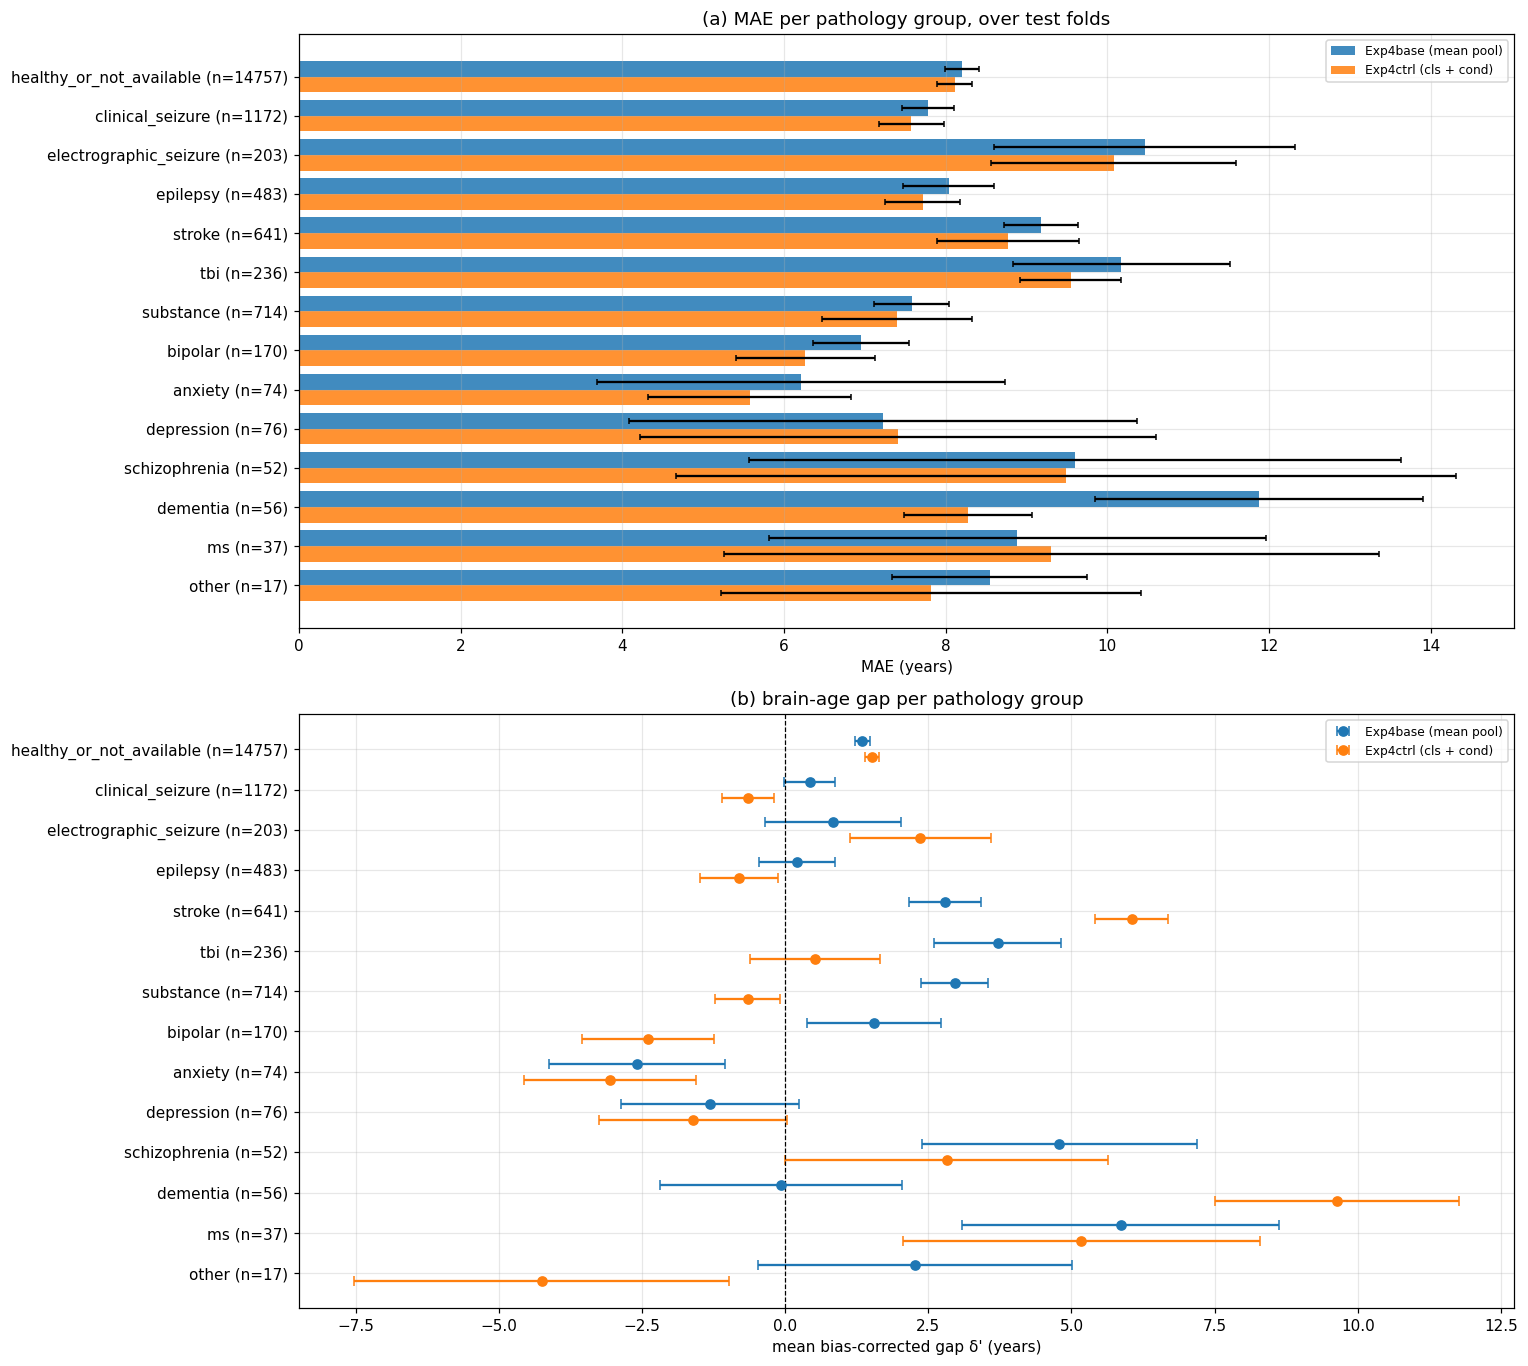

In [19]:
# experiments compared on the same recordings: greedily (most folds first) keep the experiments
# that still share at least one test fold
PATHO_EXPS, PATHO_FOLDS = [], None
for e in sorted(ORDER, key=lambda e: -oof_all[oof_all.exp == e].fold.nunique()):
    f = set(oof_all[oof_all.exp == e].fold)
    if PATHO_FOLDS is None or PATHO_FOLDS & f:
        PATHO_EXPS.append(e); PATHO_FOLDS = f if PATHO_FOLDS is None else PATHO_FOLDS & f
PATHO_EXPS = [e for e in ORDER if e in PATHO_EXPS]
print(f"Figure 5.2 / Table 5.2: {', '.join(PATHO_EXPS)} on test folds {sorted(PATHO_FOLDS)}"
      + (f"; left out (no shared fold): {', '.join(e for e in ORDER if e not in PATHO_EXPS)}"
         if len(PATHO_EXPS) < len(ORDER) else ""))
shared = oof_all[oof_all.fold.isin(PATHO_FOLDS) & oof_all.exp.isin(PATHO_EXPS)]
long_g = []
for g in groups:
    m = shared.stem.map(patho[g])
    long_g.append(shared[m].assign(group=g))
long_g = pd.concat(long_g)
fold_g = long_g.groupby(["exp", "group", "fold"]).apply(lambda x: np.abs(x.err).mean()).rename("MAE").reset_index()
fig, axes = plt.subplots(2, 1, figsize=(14, 2 * (1.5 + 0.17 * len(groups) * len(PATHO_EXPS))))
h = 0.8 / len(PATHO_EXPS)
y = np.arange(len(groups))
for j, e in enumerate(PATHO_EXPS):
    g1 = fold_g[fold_g.exp == e].groupby("group").MAE.agg(["mean", "std"]).reindex(groups)
    axes[0].barh(y + (j - (len(PATHO_EXPS) - 1) / 2) * h, g1["mean"], h, xerr=g1["std"].fillna(0), capsize=2,
                 color=COLORS.get(e), alpha=0.85, label=EXPS.get(e, e))
    ci = pd.DataFrame({g: cc.mean_ci(long_g[(long_g.exp == e) & (long_g.group == g)].bag_c) for g in groups}).T
    axes[1].errorbar(ci["mean"], y + (j - (len(PATHO_EXPS) - 1) / 2) * h, xerr=[ci["mean"] - ci["lo"], ci["hi"] - ci["mean"]],
                     fmt="o", capsize=3, color=COLORS.get(e), label=EXPS.get(e, e))
counts = long_g[long_g.exp == PATHO_EXPS[0]].groupby("group").size().reindex(groups)
for ax in axes:
    ax.set_yticks(y, [f"{g} (n={counts[g]})" for g in groups]); ax.invert_yaxis(); ax.legend(fontsize=8)
axes[0].set_xlabel("MAE (years)"); axes[0].set_title("MAE per pathology group, over test folds")
axes[1].axvline(0, color="k", ls="--", lw=0.8)
axes[1].set_xlabel("mean bias-corrected gap δ' (years)"); axes[1].set_title("brain-age gap per pathology group")
panel_labels(axes); assert_max_columns(fig); fig.tight_layout(); plt.show()

### Table 5.2. Pathology groups

Per pathology group, on the shared test folds of Figure 5.2: the number of out-of-fold recordings, their mean true age, and per experiment the
pooled out-of-fold MAE (Eq. (2.7)) and the mean bias-corrected gap $\bar\delta'$ (Eq. (4.3)) with its 95%
interval (Eq. (5.2)). Years.

In [20]:
rows = []
for g in groups:
    first = long_g[(long_g.exp == PATHO_EXPS[0]) & (long_g.group == g)]
    row = {"group": g, "n": len(first), "mean age": first.true.mean()}
    for e in PATHO_EXPS:
        s = long_g[(long_g.exp == e) & (long_g.group == g)]
        ci = cc.mean_ci(s.bag_c)
        row[f"{e} MAE"] = np.abs(s.err).mean()
        row[f"{e} δ'"] = f"{ci['mean']:+.2f} [{ci['lo']:+.2f}, {ci['hi']:+.2f}]"
    rows.append(row)
t52 = pd.DataFrame(rows).set_index("group")
numbered_table(t52, "5.2", "Pathology groups")

,n,mean age,cvbase MAE,cvbase δ',cvctrl MAE,cvctrl δ'
group,,,,,,
healthy_or_not_available,14757,52.56,8.20,"+1.35 [+1.22, +1.47]",8.11,"+1.52 [+1.39, +1.64]"
clinical_seizure,1172,48.23,7.79,"+0.43 [-0.01, +0.87]",7.57,"-0.65 [-1.10, -0.20]"
electrographic_seizure,203,55.65,10.43,"+0.83 [-0.36, +2.01]",10.08,"+2.36 [+1.13, +3.59]"
epilepsy,483,51.84,7.98,"+0.20 [-0.46, +0.87]",7.68,"-0.81 [-1.49, -0.13]"
stroke,641,62.49,9.21,"+2.79 [+2.16, +3.43]",8.76,"+6.06 [+5.42, +6.69]"
tbi,236,46.00,10.37,"+3.71 [+2.60, +4.82]",9.63,"+0.52 [-0.61, +1.66]"
substance,714,48.65,7.55,"+2.96 [+2.38, +3.54]",7.37,"-0.66 [-1.23, -0.09]"
bipolar,170,42.99,6.88,"+1.55 [+0.39, +2.71]",6.16,"-2.40 [-3.56, -1.24]"
anxiety,74,42.65,6.54,"-2.59 [-4.12, -1.05]",5.71,"-3.06 [-4.56, -1.56]"


### Figure 5.3. MAE by age decade

MAE per true-age decade, mean ± sd (Eq. (5.1)). (a) Official TUAB test, over fold models. (b) TUEG test folds,
over folds. Decades with fewer than 5 recordings in a fold are left out. Years.

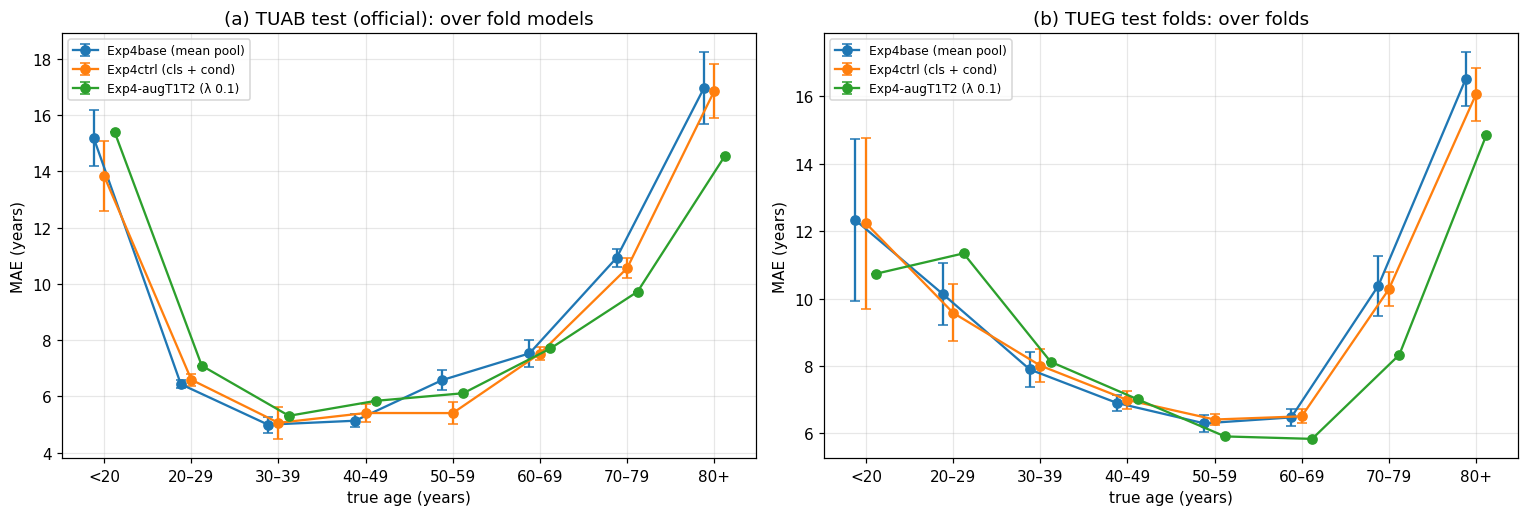

In [21]:
def decade_mae(frame):
    f = frame.assign(decade=pd.cut(frame.true, AGE_EDGES, right=False, labels=AGE_LABELS))
    g = f.groupby(["exp", "fold", "decade"], observed=True).err
    out = pd.DataFrame({"MAE": g.apply(lambda x: np.abs(x).mean()), "n": g.size()}).reset_index()
    return out[out.n >= 5]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, frame, title in ((axes[0], d[d.split == "heldout"], "TUAB test (official): over fold models"),
                         (axes[1], d[(d.split == "test") & (d.source == "TUEG")], "TUEG test folds: over folds")):
    dm = decade_mae(frame)
    for j, e in enumerate(ORDER):
        g = dm[dm.exp == e].groupby("decade", observed=True).MAE.agg(["mean", "std"])
        x = np.array([AGE_LABELS.index(i) for i in g.index]) + (j - (len(ORDER) - 1) / 2) * 0.12
        ax.errorbar(x, g["mean"], yerr=g["std"].fillna(0), fmt="o-", capsize=3, color=COLORS.get(e), label=EXPS.get(e, e))
    ax.set_xticks(range(len(AGE_LABELS)), AGE_LABELS)
    ax.set_xlabel("true age (years)"); ax.set_ylabel("MAE (years)"); ax.set_title(title); ax.legend(fontsize=8)
panel_labels(axes); assert_max_columns(fig); fig.tight_layout(); plt.show()

## 6. Findings

Generated from the tables above, so it stays in step with the scored folds when the notebook is re-run.

In [22]:
lines = []
tt = pf[(pf.cohort == "all")]
for s_name in ("TUAB test", "TUEG test", "CV test"):
    g = tt[tt.set == s_name].groupby("exp").MAE.agg(["mean", "std", "count"]).reindex(ORDER)
    best = g["mean"].idxmin()
    lines.append(f"* **{s_name}**: lowest mean MAE over fold models is `{best}` "
                 f"({g.loc[best, 'mean']:.2f}" + (f" ± {g.loc[best, 'std']:.2f}" if g.loc[best, 'count'] > 1 else "")
                 + f", K={int(g.loc[best, 'count'])}); "
                 + ", ".join(f"`{e}` {g.loc[e, 'mean']:.2f}" for e in ORDER) + " (Table 2.1).")
for e in ORDER:
    r = t23.loc[e]
    lines.append(f"* `{e}`: the median ensemble of {int(r.K)} fold models scores {r['TUAB ens. median']:.2f} on the TUAB "
                 f"test vs. {r['TUAB single model']:.2f} for a single fold model on average "
                 f"(normal {r['TUAB ens. normal']:.2f}, abnormal {r['TUAB ens. abnormal']:.2f}; Table 2.3).")
w_ = t31[t31.index.str.startswith("within")]
b_ = t31[t31.index.str.startswith("between")]
if len(w_):
    lines.append(f"* Within an experiment, fold models' errors correlate at r_err {w_.r_err.min():.2f}–{w_.r_err.max():.2f} "
                 f"and agree within 5 years on {w_.A_5y.min():.0%}–{w_.A_5y.max():.0%} of TUAB test recordings"
                 + (f"; between experiments r_err {b_.r_err.min():.2f}–{b_.r_err.max():.2f}, "
                    f"A_5 {b_.A_5y.min():.0%}–{b_.A_5y.max():.0%}" if len(b_) else "") + " (Table 3.1).")
for _, r in t32.iterrows():
    lines.append(f"* {r['set']}: `{r.a}` − `{r.b}` ΔMAE {r['ΔMAE']:+.2f} {r['95% CI']}, P({r.a} better) {r['P(a better)']:.2f} (Table 3.2).")
GAP_EXP = REF_EXP if REF_EXP in PATHO_EXPS else PATHO_EXPS[0]
top = t52[f"{GAP_EXP} δ'"]
vals = top.str.split().str[0].astype(float).sort_values()
lines.append(f"* Bias-corrected brain-age gap ({GAP_EXP}, Table 5.2): oldest-looking groups "
             + ", ".join(f"{g} {v:+.2f}" for g, v in vals[::-1].head(3).items())
             + "; youngest-looking " + ", ".join(f"{g} {v:+.2f}" for g, v in vals.head(2).items()) + " years.")
display(Markdown("\n".join(lines)))

* **TUAB test**: lowest mean MAE over fold models is `cvctrl` (7.28 ± 0.20, K=3); `cvbase` 7.49, `cvctrl` 7.28, `cvaug` 7.43 (Table 2.1).
* **TUEG test**: lowest mean MAE over fold models is `cvaug` (7.97, K=1); `cvbase` 8.27, `cvctrl` 8.19, `cvaug` 7.97 (Table 2.1).
* **CV test**: lowest mean MAE over fold models is `cvaug` (7.92, K=1); `cvbase` 8.18, `cvctrl` 8.09, `cvaug` 7.92 (Table 2.1).
* `cvbase`: the median ensemble of 5 fold models scores 7.44 on the TUAB test vs. 7.49 for a single fold model on average (normal 5.75, abnormal 9.46; Table 2.3).
* `cvctrl`: the median ensemble of 3 fold models scores 7.15 on the TUAB test vs. 7.28 for a single fold model on average (normal 5.37, abnormal 9.27; Table 2.3).
* `cvaug`: the median ensemble of 1 fold models scores 7.43 on the TUAB test vs. 7.43 for a single fold model on average (normal 5.61, abnormal 9.60; Table 2.3).
* Within an experiment, fold models' errors correlate at r_err 0.94–0.97 and agree within 5 years on 90%–93% of TUAB test recordings; between experiments r_err 0.94–0.95, A_5 88%–89% (Table 3.1).
* TUAB test (median ens.): `cvbase` − `cvctrl` ΔMAE +0.29 [+0.02, +0.58], P(cvbase better) 0.02 (Table 3.2).
* TUEG test (out-of-fold, folds 2,3,4): `cvbase` − `cvctrl` ΔMAE +0.14 [+0.08, +0.18], P(cvbase better) 0.00 (Table 3.2).
* TUAB test (median ens.): `cvbase` − `cvaug` ΔMAE +0.01 [-0.30, +0.32], P(cvbase better) 0.46 (Table 3.2).
* TUEG test (out-of-fold, folds 1): `cvbase` − `cvaug` ΔMAE +0.21 [+0.12, +0.29], P(cvbase better) 0.00 (Table 3.2).
* TUAB test (median ens.): `cvctrl` − `cvaug` ΔMAE -0.28 [-0.59, +0.02], P(cvctrl better) 0.96 (Table 3.2).
* Bias-corrected brain-age gap (cvbase, Table 5.2): oldest-looking groups ms +5.86, schizophrenia +4.79, tbi +3.71; youngest-looking anxiety -2.59, depression -1.31 years.